# Structural analysis of the OH\*+H\* rankings on the Ni nanoparticles

This notebook collects every structural analysis of the ranked OH\*+H\* candidates on the
Ni nanoparticles (NPs): the DFT-validated $\mathrm{Ni}_{55}$, $\mathrm{Ni}_{91}$ and $\mathrm{Ni}_{130}$ in this folder and the
prediction-only NPs in `NPs_prediction_only/`. Energy and retention validation stay in
`analysis_energy_test_systems.py` and `analysis_retention_test_systems.py`.

| Section | Output (written to this folder) |
|---|---|
| 1. Retained motif shares | `retained_motif_shares.txt`, `retained_motif_shares.csv` |
| 2. Motif-resolved GCN slopes | `gcn_slopes.csv` |
| 3. Figure 5 | `Figure5_results.pdf` |
| 4. Retained-motif $\mathrm{E}_\mathrm{ads}$ histograms (SI) | `SI_retained_motif_histograms.pdf` |
| 5. $\mathrm{E}_\mathrm{ads}$ vs $\mathrm{GCN}_\mathrm{O}$ / $\mathrm{GCN}_\mathrm{H}$ per NP (SI) | `SI_Eads_vs_GCN_O.pdf`, `SI_Eads_vs_GCN_H.pdf` |
| 6. $\mathrm{Ni}_{55}$ and $\mathrm{Ni}_{91}$ GCN panels (SI) | `GCN_Ni55_Ni91_SI.pdf` |
| 7. $\mathrm{GCN}_\mathrm{O}$/$\mathrm{GCN}_\mathrm{H}$ separability, $\mathrm{Ni}_{91}$ + $\mathrm{Ni}_{130}$ (Figure S12) | `SI_gcn_separability_DFT.pdf` |
| 8. $\mathrm{GCN}_\mathrm{O}$ vs $\mathrm{GCN}_\mathrm{H}$ joint slopes, all NPs (check, not in the paper) | `gcn_O_vs_H_slopes_*.csv`, `SI_gcn_O_vs_H_slopes.pdf` |
| 9. Motif-slope spread vs surface morphology (Figure S15) | `slope_vs_morphology_summary.csv`, `slope_morphology_correlations.csv`, `SI_slope_separation_vs_morphology.pdf` |
| 10. Strongest-binding retained BH/HH/TH per NP | printed only |

**Inputs**
- `NiXX/NiXX_ranked_candidates.csv` (DFT-validated) and `NPs_prediction_only/NiXX/NiXX_ranked_candidates.csv`.
  A prediction-only folder without its CSV is skipped with a message.
- `../ML_relaxed_bare_geom/MACE/testing/NiXX_MACE_opt.xyz`: the MACE-relaxed bare NPs. The anchor indices in
  the rankings are zero-based indices into these structures.

**Conventions**
- Retained candidates: $s_\mathrm{ret} \geq 0.80$. Every analysis below uses retained candidates only.
- Site GCN: $\mathrm{GCN(site)} = \sum_{j \in \mathrm{NN(site)}} \mathrm{CN}_j / \mathrm{CN}_\mathrm{max}$, where NN(site) is the union of
  the neighbours of all anchor Ni atoms minus the anchors themselves; Ni–Ni cutoff 3.0 Å;
  $\mathrm{CN}_\mathrm{max}$ = 12, 18, 22, 26 for T, B, H, F sites.
- A motif slope is "usable" only with ≥ 30 candidates and ≥ 10 distinct GCN values. $\mathrm{Ni}_{55}$ never qualifies
  (its symmetry leaves 1–2 distinct GCN values per motif).

Run the notebook top to bottom (about 30 s).

## 0. Setup

In [1]:
from __future__ import annotations

import ast
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.io import read
from ase.neighborlist import neighbor_list
from matplotlib.colors import to_hex, to_rgb
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MultipleLocator
from scipy.stats import norm, pearsonr, spearmanr, t as student_t, ttest_rel, wilcoxon

try:
    from scipy.special import sph_harm_y

    def spherical_harmonic(l, m, polar, azimuth):
        return sph_harm_y(l, m, polar, azimuth)

except ImportError:  # SciPy < 1.15
    from scipy.special import sph_harm

    def spherical_harmonic(l, m, polar, azimuth):
        return sph_harm(m, l, azimuth, polar)

%matplotlib inline

In [2]:
HERE = Path.cwd()
DFT_SYSTEMS = ("Ni55", "Ni91", "Ni130")
PREDICTION_ONLY_DIR = HERE / "NPs_prediction_only"
BARE_STRUCTURE_DIR = HERE.parent / "ML_relaxed_bare_geom" / "MACE" / "testing"
if not (HERE / "Ni130").is_dir() or not BARE_STRUCTURE_DIR.is_dir():
    raise FileNotFoundError("Run this notebook from the repository test_systems directory")

ENERGY_COL = "pred_Eads_eV"
RETENTION_MIN = 0.80
NI_NI_CUTOFF = 3.0
GCN_CN_MAX = {"T": 12, "B": 18, "H": 22, "F": 26}

TARGET_SYSTEM = "Ni130"           # particle shown in the top row of Figure 5
MAIN_MOTIFS = ["BH", "HH", "TH"]
FIG5_MOTIF_MIN_SHARE = 0.10       # Figure 5: motifs with >= 10% of Ni130 retained candidates
SI_MOTIF_MIN_SHARE = 0.05         # SI panels: motifs with > 5% of each NP's retained candidates

MIN_GCN_UNIQUE_FOR_SLOPE = 10
MIN_POINTS_FOR_SLOPE = 30
MIN_POINTS_FOR_SCATTER = 20       # scatter panels skip motifs with fewer points
MIN_GCN_UNIQUE_FOR_LINE = 3       # ... and draw "--" instead of a fit below this

In [3]:
MOTIF_COLORS = {
    "BH": "seagreen", "HH": "violet", "TH": "gold",
    # Remaining motifs, chosen not to clash with the three above.
    "HF": "#CC3311", "BF": "#AA6622", "BB": "#0077BB", "BT": "#009988",
    "HB": "#33BBEE", "HT": "#EE7733", "TB": "#000080", "TF": "#AACC00",
    "TT": "#BBBBBB", "FB": "#882255", "FF": "#7733BB", "FH": "#EE3377",
    "FT": "#555555",
}
COL_DFT, COL_PRED = "coral", "deepskyblue"
# Particle colours of the bare-surface figures (analyze_bare_Ni_for_paper.py).
NP_FACE_COLORS = {
    "Ni55": "teal", "Ni91": "darkorange", "Ni130": "darkviolet", "Ni218": "dimgray",
    "Ni442": "yellowgreen", "Ni524": "mediumturquoise", "Ni686": "indianred",
    "Ni864": "mediumslateblue", "Ni1141": "black", "Ni1314": "purple",
    "Ni1391": "darkkhaki", "Ni3007": "cyan",
}

FONT = {"base": 19, "axis_label": 20, "tick": 18, "legend": 16, "legend_small": 15, "annot": 19}

# Figure 5 and its SI companions (sections 3-5, 8).
STYLE_PAPER = {
    "font.family": "sans-serif",
    "font.size": FONT["base"], "axes.labelsize": FONT["axis_label"],
    "axes.titlesize": FONT["axis_label"], "xtick.labelsize": FONT["tick"],
    "ytick.labelsize": FONT["tick"], "legend.fontsize": FONT["legend"],
    "legend.frameon": True, "legend.edgecolor": "0.65", "legend.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.9,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.minor.size": 2.2, "ytick.minor.size": 2.2,
    "xtick.minor.width": 0.6, "ytick.minor.width": 0.6,
    "lines.linewidth": 1.8, "patch.linewidth": 1.4,
}
# Ni55/Ni91 SI panels and Figure S12 (sections 6-7).
STYLE_GCN_SI = {
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 19, "axes.labelsize": 20, "xtick.labelsize": 18, "ytick.labelsize": 18,
    "legend.fontsize": 15, "legend.frameon": True, "legend.edgecolor": "0.65",
    "legend.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.9, "xtick.direction": "out", "ytick.direction": "out",
}
# Figure S15, matching the bare-surface figures (section 9).
STYLE_MORPHOLOGY = {
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans", "axes.linewidth": 1.0,
    "pdf.fonttype": 42, "ps.fonttype": 42,
}

ENERGY_LABEL = r"Predicted $\mathrm{E}_{\mathrm{ads}}$ (eV)"
GCN_LABEL = {"o_site_gcn": r"$\mathrm{GCN}_\mathrm{O}$", "h_site_gcn": r"$\mathrm{GCN}_\mathrm{H}$"}
GCN_ATOM = {"o_site_gcn": "O", "h_site_gcn": "H"}

### Shared helpers

Geometry and site GCN, data loading, OLS with robust standard errors, and plotting utilities
used by several sections.

In [4]:
def read_xyz_positions(path: Path) -> np.ndarray:
    """Cartesian coordinates from a standard XYZ/extxyz file."""
    lines = path.read_text().splitlines()
    n_atoms = int(lines[0])
    coordinates = [[float(v) for v in line.split()[1:4]] for line in lines[2 : 2 + n_atoms]]
    if len(coordinates) != n_atoms:
        raise ValueError(f"Expected {n_atoms} coordinates in {path}, found {len(coordinates)}")
    return np.asarray(coordinates, dtype=float)


def bare_structure(system: str) -> Path:
    return BARE_STRUCTURE_DIR / f"{system}_MACE_opt.xyz"


def parse_anchor_indices(value) -> list[int]:
    """Parse an anchor list such as ``[12, 24]`` from the ranking CSV."""
    anchors = ast.literal_eval(str(value))
    if not isinstance(anchors, (list, tuple)):
        raise ValueError(f"Anchor entry is not a list: {value!r}")
    return [int(index) for index in anchors]


def build_coordination_data(positions: np.ndarray, cutoff: float = NI_NI_CUTOFF):
    """Full CN of every atom and its Ni-neighbour set."""
    distance = np.linalg.norm(positions[:, None, :] - positions[None, :, :], axis=-1)
    bonded = (distance <= cutoff) & (distance > 1.0e-12)
    return bonded.sum(axis=1).astype(int), [set(np.flatnonzero(row)) for row in bonded]


def site_gcn(anchors, site_type, full_cn, neighbour_sets) -> float:
    """GCN of a complete T/B/H/F adsorption site (anchors excluded from NN(site))."""
    site_type = str(site_type).strip().upper()
    neighbours: set[int] = set()
    for anchor in anchors:
        neighbours.update(neighbour_sets[anchor])
    neighbours.difference_update(anchors)
    if not neighbours:
        return float("nan")
    return float(full_cn[list(neighbours)].sum()) / GCN_CN_MAX[site_type]


def n_atoms(system: str) -> int:
    return int(system[2:])


def display_name(system: str) -> str:
    return rf"Ni$_{{{n_atoms(system)}}}$"

In [5]:
def discover_systems() -> list[tuple[str, Path, bool]]:
    """(system, ranking CSV, DFT-validated) for every available NP, by size."""
    systems = [(s, HERE / s / f"{s}_ranked_candidates.csv", True) for s in DFT_SYSTEMS]
    for folder in sorted(PREDICTION_ONLY_DIR.glob("Ni*")):
        csv = folder / f"{folder.name}_ranked_candidates.csv"
        if not csv.is_file():
            print(f"Skipping {folder.name}: {csv.name} not found")
            continue
        systems.append((folder.name, csv, False))
    for system, csv, _ in systems:
        if not csv.is_file():
            raise FileNotFoundError(csv)
    return sorted(systems, key=lambda item: n_atoms(item[0]))


def load_system(system: str, csv: Path, dft_validated: bool) -> pd.DataFrame:
    """All retained candidates of one NP, with O- and H-site GCN."""
    candidates = pd.read_csv(csv)
    required = {"motif", "o_type", "h_type", "o_anchor_idx", "h_anchor_idx",
                "site_distance_A", ENERGY_COL, "retention_probability"}
    missing = required.difference(candidates.columns)
    if missing:
        raise ValueError(f"{csv}: missing required columns {sorted(missing)}")
    retained = candidates[candidates["retention_probability"] >= RETENTION_MIN].copy()

    positions = read_xyz_positions(bare_structure(system))
    full_cn, neighbour_sets = build_coordination_data(positions)
    for site in ("o", "h"):
        anchors = retained[f"{site}_anchor_idx"].map(parse_anchor_indices)
        flat = [index for entry in anchors for index in entry]
        if min(flat) < 0 or max(flat) >= len(positions):
            raise IndexError(f"{system}: anchor indices incompatible with the bare geometry")
        retained[f"{site}_site_gcn"] = [
            site_gcn(entry, kind, full_cn, neighbour_sets)
            for entry, kind in zip(anchors, retained[f"{site}_type"])
        ]
    retained["system"] = system
    retained["n_atoms"] = n_atoms(system)
    retained["dft_validated"] = dft_validated
    retained.attrs["n_candidates"] = len(candidates)
    return retained


def select_motifs(data: pd.DataFrame, min_share: float, strict: bool) -> list[str]:
    """Retained motifs above (strict) or at least at min_share, largest first."""
    share = data["motif"].value_counts(normalize=True)
    return list(share[share > min_share if strict else share >= min_share].index)

In [6]:
def ols_slope(x: np.ndarray, y: np.ndarray) -> tuple[float, float, float]:
    """Slope, intercept and slope standard error of y = a + b x."""
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (slope * x + intercept)
    sxx = np.sum((x - x.mean()) ** 2)
    se = np.sqrt(np.sum(residual**2) / (len(x) - 2) / sxx) if sxx > 0 else np.nan
    return float(slope), float(intercept), float(se)


def ols(X: np.ndarray, y: np.ndarray):
    """Coefficients, residuals and (X'X)^-1."""
    xtx_inv = np.linalg.inv(X.T @ X)
    beta = xtx_inv @ X.T @ y
    return beta, y - X @ beta, xtx_inv


def hc3_cov(X, residual, xtx_inv) -> np.ndarray:
    """Heteroscedasticity-robust (HC3) covariance of OLS coefficients."""
    leverage = np.einsum("ij,jk,ik->i", X, xtx_inv, X)
    weights = (residual / (1.0 - leverage)) ** 2
    return xtx_inv @ (X.T * weights) @ X @ xtx_inv


def cluster_cov(X, residual, xtx_inv, clusters, n_params: int) -> np.ndarray:
    """CR1 cluster-robust covariance; n_params counts absorbed fixed effects."""
    meat = np.zeros((X.shape[1], X.shape[1]))
    labels = np.unique(clusters)
    for label in labels:
        score = X[clusters == label].T @ residual[clusters == label]
        meat += np.outer(score, score)
    n, g = len(residual), len(labels)
    return g / (g - 1) * (n - 1) / (n - n_params) * xtx_inv @ meat @ xtx_inv

In [7]:
def motif_color(motif: str) -> str:
    return MOTIF_COLORS.get(motif, "#444444")


def add_minor_ticks(axis, x: bool = True, y: bool = True, length: float | None = 4) -> None:
    for enabled, ax_obj, name in ((x, axis.xaxis, "x"), (y, axis.yaxis, "y")):
        if enabled:
            ax_obj.set_minor_locator(AutoMinorLocator(2))
            if length is not None:
                axis.tick_params(axis=name, which="minor", length=length)


def padded_limits(values: np.ndarray, pad: float = 0.045) -> tuple[float, float]:
    values = values[np.isfinite(values)]
    low, high = float(values.min()), float(values.max())
    margin = pad * (high - low) if high > low else 0.05
    return low - margin, high + margin


def scatter_with_fits(axis, data, motifs, descriptor, ms=10, alpha=0.45,
                      min_points=MIN_POINTS_FOR_SCATTER, n_fit=60) -> None:
    """Motif-resolved E_ads vs GCN cloud plus one OLS line per motif."""
    for motif in motifs:
        subset = data[data["motif"] == motif]
        if len(subset) < min_points:
            continue
        x = subset[descriptor].to_numpy(dtype=float)
        y = subset[ENERGY_COL].to_numpy(dtype=float)
        finite = np.isfinite(x) & np.isfinite(y)
        x, y = x[finite], y[finite]
        color = motif_color(motif)
        axis.plot(x, y, ".", ms=ms, alpha=alpha, color=color, markeredgewidth=0, zorder=1)
        if len(np.unique(x)) < MIN_GCN_UNIQUE_FOR_LINE:
            # Ni55-type case: too few distinct GCN values for a meaningful line.
            axis.plot([], [], color=color, lw=2.5, label=f"{motif}  --")
            continue
        slope, intercept, _ = ols_slope(x, y)
        x_fit = np.linspace(x.min(), x.max(), n_fit)
        axis.plot(x_fit, slope * x_fit + intercept, color=color, lw=2.5,
                  solid_capstyle="round", label=f"{motif}  {slope:.3f}", zorder=3,
                  path_effects=[path_effects.withStroke(linewidth=7.3, foreground="white")])


def slope_legend_title(descriptor: str) -> str:
    atom = GCN_ATOM[descriptor]
    return rf"$\mathrm{{dE}}_\mathrm{{ads}}/\mathrm{{dGCN}}_\mathrm{{{atom}}}$ (eV/GCN)"


def save(figure, path: Path) -> None:
    """Write the PDF and show the figure inline."""
    figure.savefig(path, bbox_inches="tight")
    print(f"Wrote {path.name}")
    plt.show()

### Load all NPs

One DataFrame of retained candidates per NP, with `o_site_gcn` and `h_site_gcn`; `pooled` concatenates them.

In [8]:
retained: dict[str, pd.DataFrame] = {}
for system, csv, dft_validated in discover_systems():
    retained[system] = load_system(system, csv, dft_validated)
    status = "DFT-validated" if dft_validated else "prediction-only"
    print(f"{system:>7} ({status:<15}): {retained[system].attrs['n_candidates']:>7,} candidates, "
          f"{len(retained[system]):>6,} retained")
pooled = pd.concat(retained.values(), ignore_index=True)

   Ni55 (DFT-validated  ):  19,680 candidates,  3,480 retained
   Ni91 (DFT-validated  ):  26,940 candidates,  2,718 retained
  Ni130 (DFT-validated  ):  46,378 candidates,  3,834 retained
  Ni218 (prediction-only):  67,020 candidates,  5,449 retained
  Ni442 (prediction-only):  87,178 candidates,  3,297 retained
  Ni524 (prediction-only): 110,892 candidates,  6,056 retained
  Ni686 (prediction-only): 122,384 candidates,  5,124 retained
  Ni864 (prediction-only): 187,186 candidates,  4,333 retained
 Ni1141 (prediction-only): 181,876 candidates,  9,827 retained
 Ni1314 (prediction-only): 187,498 candidates,  9,802 retained
 Ni1391 (prediction-only): 215,448 candidates,  7,123 retained
 Ni3007 (prediction-only): 146,914 candidates,  4,145 retained


## 1. Retained motif shares

Per NP, the count and share of every retained motif. The motifs used in Figure 5 are those with ≥ 10% of
$\mathrm{Ni}_{130}$'s retained candidates. The SI panels show, for each NP, the motifs above 5%.

In [9]:
fig5_motifs = select_motifs(retained[TARGET_SYSTEM], FIG5_MOTIF_MIN_SHARE, strict=False)
si_motifs = {s: select_motifs(d, SI_MOTIF_MIN_SHARE, strict=True) for s, d in retained.items()}

rows = []
blocks = [
    f"Retained motif shares (s_ret >= {RETENTION_MIN:.2f}). "
    f"Figure 5 motifs (>= {FIG5_MOTIF_MIN_SHARE:.0%} of {TARGET_SYSTEM}): {', '.join(fig5_motifs)}. "
    f"SI panels: motifs > {SI_MOTIF_MIN_SHARE:.0%} of each particle."
]
for system, data in retained.items():
    counts = data["motif"].value_counts()
    share = counts / counts.sum()
    status = "DFT-validated" if data["dft_validated"].iloc[0] else "prediction-only"
    table = pd.DataFrame({
        "count": counts,
        "share": (100.0 * share).map(lambda value: f"{value:.2f}%"),
        f"SI (>{SI_MOTIF_MIN_SHARE:.0%})": np.where(share > SI_MOTIF_MIN_SHARE, "yes", ""),
    })
    table.index.name = "motif"
    blocks.append(f"=== {system} ({status}): {data.attrs['n_candidates']:,} candidates, "
                  f"{len(data):,} retained ===\n{table.to_string()}")
    for motif, count in counts.items():
        rows.append({
            "system": system, "n_atoms": n_atoms(system),
            "dft_validated": bool(data["dft_validated"].iloc[0]),
            "n_candidates": data.attrs["n_candidates"], "n_retained": len(data),
            "motif": motif, "count": int(count), "share": float(share[motif]),
            "in_si_panels": bool(share[motif] > SI_MOTIF_MIN_SHARE),
            "in_figure5": motif in fig5_motifs,
        })
text = "\n\n".join(blocks)
print(text)
(HERE / "retained_motif_shares.txt").write_text(text + "\n")
pd.DataFrame(rows).to_csv(HERE / "retained_motif_shares.csv", index=False)

Retained motif shares (s_ret >= 0.80). Figure 5 motifs (>= 10% of Ni130): BH, HH, TH. SI panels: motifs > 5% of each particle.

=== Ni55 (DFT-validated): 19,680 candidates, 3,480 retained ===
       count   share SI (>5%)
motif                        
BH      1620  46.55%      yes
HH      1320  37.93%      yes
TH       540  15.52%      yes

=== Ni91 (DFT-validated): 26,940 candidates, 2,718 retained ===
       count   share SI (>5%)
motif                        
BH      1271  46.76%      yes
HH       888  32.67%      yes
TH       350  12.88%      yes
BF        56   2.06%         
HF        47   1.73%         
HB        37   1.36%         
FH        20   0.74%         
TB        17   0.63%         
TF        12   0.44%         
BB        10   0.37%         
HT         5   0.18%         
FF         2   0.07%         
BT         2   0.07%         
FB         1   0.04%         

=== Ni130 (DFT-validated): 46,378 candidates, 3,834 retained ===
       count   share SI (>5%)
motif            

## 2. Motif-resolved GCN slopes

OLS slopes $\mathrm{dE_{ads}/dGCN_O}$ and $\mathrm{dE_{ads}/dGCN_H}$ for each NP, for the Figure 5 motifs plus that NP's SI motifs.
These are the slopes plotted in Figure 5(e) and used in section 9.

In [10]:
def slope_table(motifs_by_system: dict[str, list[str]]) -> pd.DataFrame:
    rows = []
    for system, motifs in motifs_by_system.items():
        data = retained[system]
        for motif in motifs:
            subset = data[data["motif"] == motif]
            for descriptor in ("o_site_gcn", "h_site_gcn"):
                x = subset[descriptor].to_numpy(dtype=float)
                y = subset[ENERGY_COL].to_numpy(dtype=float)
                finite = np.isfinite(x) & np.isfinite(y)
                x, y = x[finite], y[finite]
                n_unique = len(np.unique(x))
                usable = n_unique >= MIN_GCN_UNIQUE_FOR_SLOPE and len(x) >= MIN_POINTS_FOR_SLOPE
                slope, _, se = ols_slope(x, y) if usable else (np.nan, np.nan, np.nan)
                rows.append({
                    "system": system, "n_atoms": n_atoms(system),
                    "dft_validated": bool(data["dft_validated"].iloc[0]),
                    "motif": motif, "descriptor": descriptor, "n": len(x),
                    "n_unique_gcn": n_unique, "slope": slope, "slope_se": se, "usable": usable,
                })
    return pd.DataFrame(rows).sort_values(["descriptor", "motif", "n_atoms"])


slopes = slope_table({s: list(dict.fromkeys(fig5_motifs + si_motifs[s])) for s in retained})
slopes.to_csv(HERE / "gcn_slopes.csv", index=False)
print("Wrote gcn_slopes.csv")
(slopes[slopes["usable"]]
 .pivot_table(index="system", columns=["descriptor", "motif"], values="slope", sort=False)
 .loc[[s for s in retained if s in set(slopes.loc[slopes["usable"], "system"])]]
 .round(3))

Wrote gcn_slopes.csv


descriptor h_site_gcn                     o_site_gcn                     
motif              BH    HF     HH     TH         BH     HF     HH     TH
system                                                                   
Ni91            0.014   NaN  0.011 -0.006      0.106    NaN  0.078  0.084
Ni130           0.001   NaN -0.004  0.014      0.119    NaN  0.088  0.092
Ni218           0.013   NaN  0.007  0.004      0.102    NaN  0.077  0.090
Ni442           0.040   NaN  0.012  0.056      0.151    NaN  0.103  0.101
Ni524           0.043   NaN  0.018  0.051      0.112    NaN  0.075  0.076
Ni686           0.055   NaN  0.028  0.043      0.121    NaN  0.093  0.091
Ni864           0.045  0.07  0.012  0.053      0.146  0.168  0.094  0.121
Ni1141          0.022   NaN  0.009  0.019      0.081    NaN  0.057  0.069
Ni1314          0.036   NaN  0.023  0.026      0.095    NaN  0.076  0.064
Ni1391          0.043   NaN  0.022  0.080      0.144    NaN  0.083  0.111
Ni3007          0.063   NaN  0.053  0.088      0.119    NaN  0.102  0.148

## 3. Figure 5

Top row: $\mathrm{Ni}_{130}$ retained-motif $\mathrm{E}_\mathrm{ads}$ distributions and $\mathrm{E}_\mathrm{ads}$ vs $\mathrm{GCN}_\mathrm{O}$/$\mathrm{GCN}_\mathrm{H}$.
Bottom row: $\mathrm{GCN}_\mathrm{O}$ of all retained candidates vs NP size, and the within-motif
$\mathrm{dE_{ads}/dGCN_O}$ slopes (± SE) vs NP size.

Wrote Figure5_results.pdf


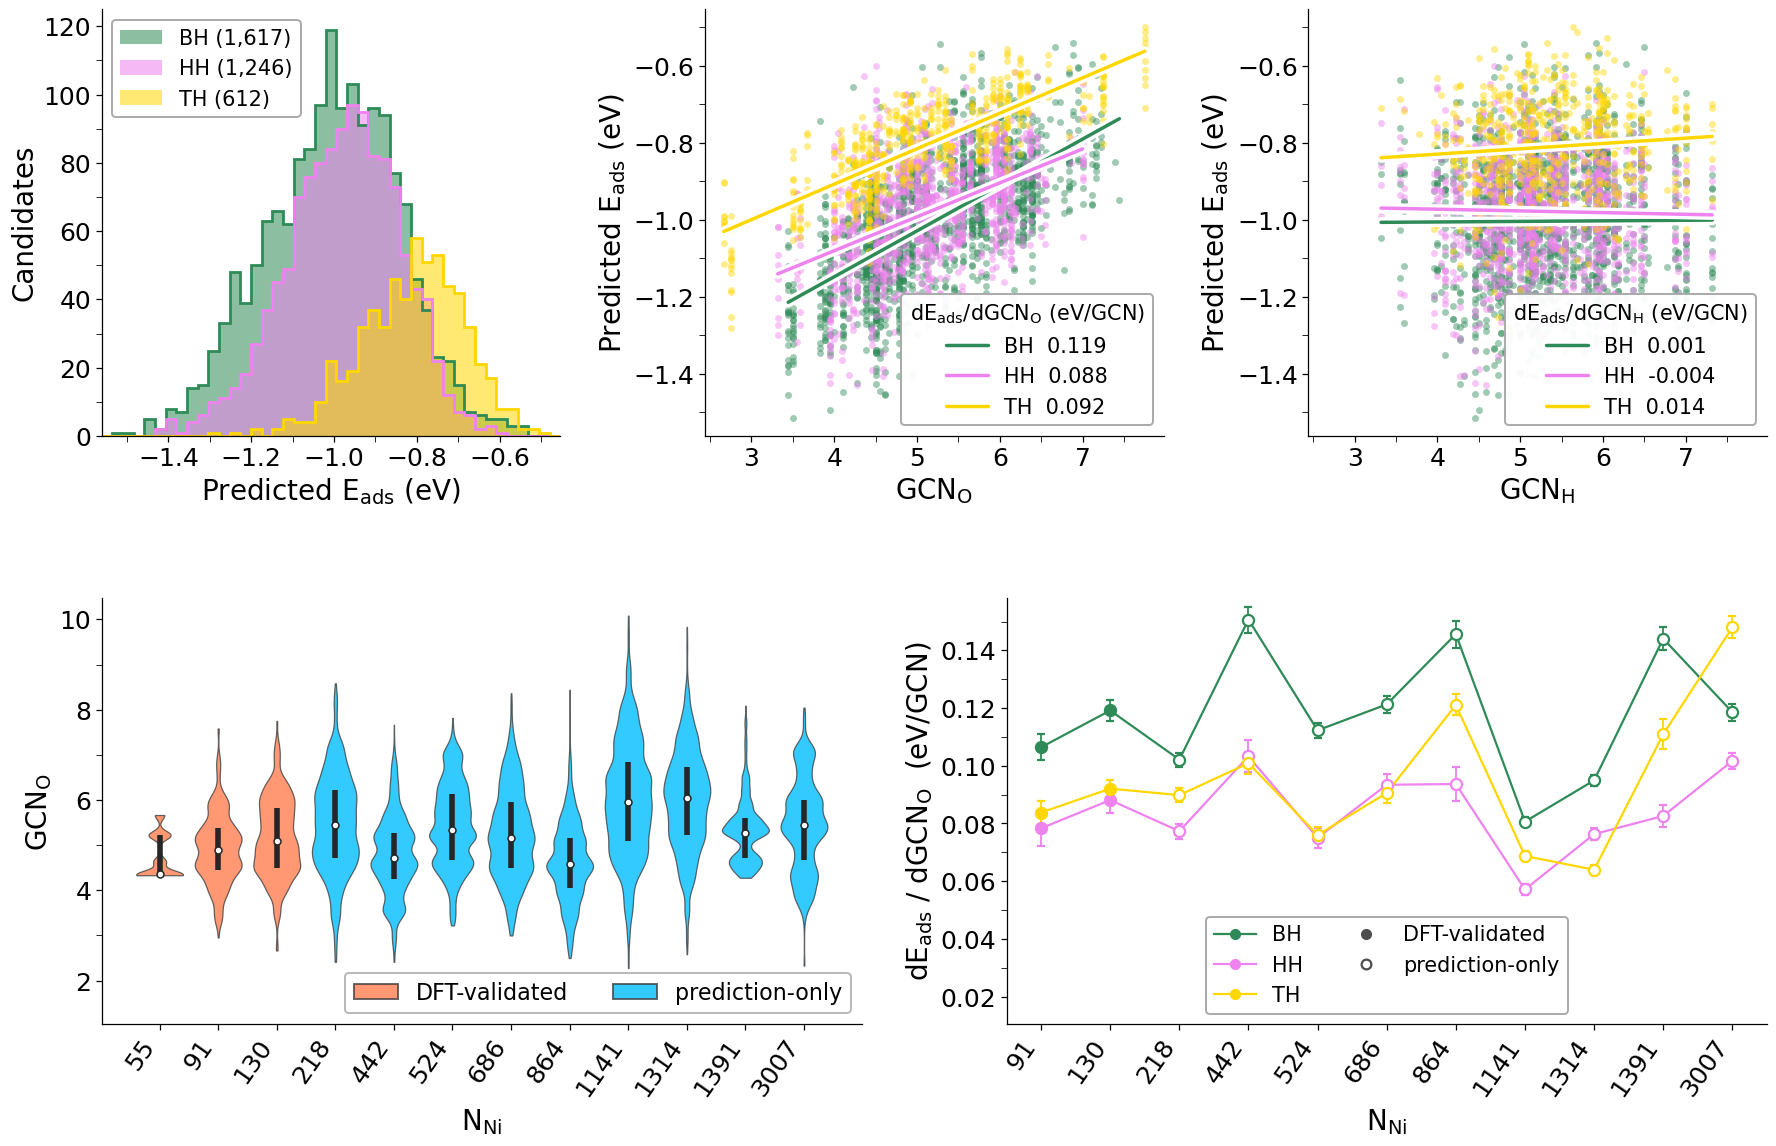

In [11]:
def make_figure5(motifs: list[str]) -> None:
    systems = list(retained)
    is_dft = {s: bool(retained[s]["dft_validated"].iloc[0]) for s in systems}
    target = retained[TARGET_SYSTEM]
    target_major = target[target["motif"].isin(motifs)].copy()
    ok = slopes[(slopes["descriptor"] == "o_site_gcn") & slopes["motif"].isin(motifs)
                & slopes["usable"]].copy()

    energy_limits = padded_limits(target_major[ENERGY_COL].to_numpy(dtype=float))
    gcn_limits = padded_limits(np.concatenate([
        target_major["o_site_gcn"].to_numpy(dtype=float),
        target_major["h_site_gcn"].to_numpy(dtype=float)]))

    with plt.rc_context(STYLE_PAPER):
        fig = plt.figure(figsize=(18.2, 11.6))
        gs = gridspec.GridSpec(2, 6, figure=fig, left=0.07, right=0.985, bottom=0.09,
                               top=0.965, hspace=0.38, wspace=0.92)

        # (a) Ni130 predicted adsorption-energy distributions by motif.
        ax = fig.add_subplot(gs[0, 0:2])
        bins = np.linspace(*energy_limits, 44)
        for motif in motifs:
            values = target_major.loc[target_major["motif"] == motif, ENERGY_COL].to_numpy(float)
            ax.hist(values, bins=bins, color=motif_color(motif), alpha=0.55,
                    label=f"{motif} ({len(values):,})")
            ax.hist(values, bins=bins, histtype="step", color=motif_color(motif), lw=2.0)
        ax.set_xlim(*energy_limits)
        ax.set_xlabel(ENERGY_LABEL)
        ax.set_ylabel("Candidates")
        ax.legend(fontsize=FONT["legend_small"], framealpha=0.95)
        add_minor_ticks(ax)

        # (b), (c) Ni130 motif-resolved GCN--energy clouds and OLS fits.
        for start, stop, descriptor in ((2, 4, "o_site_gcn"), (4, 6, "h_site_gcn")):
            ax = fig.add_subplot(gs[0, start:stop])
            scatter_with_fits(ax, target_major, motifs, descriptor)
            ax.set_xlim(*gcn_limits)
            ax.set_ylim(*energy_limits)
            ax.set_xlabel(GCN_LABEL[descriptor])
            ax.set_ylabel(ENERGY_LABEL)
            ax.legend(fontsize=FONT["legend_small"], loc="lower right",
                      title=slope_legend_title(descriptor),
                      title_fontsize=FONT["legend_small"], framealpha=0.95)
            add_minor_ticks(ax)

        # (d) All retained motifs pooled into one O-site-GCN violin per particle.
        ax = fig.add_subplot(gs[1, 0:3])
        violin_data = [retained[s]["o_site_gcn"].dropna().to_numpy(float) for s in systems]
        parts = ax.violinplot(violin_data, positions=range(len(systems)), widths=0.80,
                              showextrema=False, showmedians=False)
        for body, system in zip(parts["bodies"], systems):
            body.set_facecolor(COL_DFT if is_dft[system] else COL_PRED)
            body.set_edgecolor("0.25")
            body.set_linewidth(0.9)
            body.set_alpha(0.80)
        for index, values in enumerate(violin_data):
            q1, median, q3 = np.percentile(values, [25, 50, 75])
            ax.vlines(index, q1, q3, color="0.15", lw=4.0, zorder=3)
            ax.plot(index, median, "o", ms=5.0, color="white", mec="0.15", mew=1.1, zorder=4)
        ax.set_xticks(range(len(systems)))
        ax.set_xticklabels([str(n_atoms(s)) for s in systems], rotation=55, ha="right",
                           fontsize=FONT["tick"])
        ax.set_xlabel(r"$\mathrm{N}_\mathrm{Ni}$")
        ax.set_ylabel(GCN_LABEL["o_site_gcn"])
        lower, upper = ax.get_ylim()  # empty band below the violins for the legend
        ax.set_ylim(lower - 0.10 * (upper - lower), upper)
        handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="0.25", alpha=0.80) for c in (COL_DFT, COL_PRED)]
        ax.legend(handles, ["DFT-validated", "prediction-only"], fontsize=FONT["legend"],
                  loc="lower right", ncol=2)
        add_minor_ticks(ax, x=False)

        # (e) Within-motif Eads/GCN_O slope versus particle size.
        ax = fig.add_subplot(gs[1, 3:6])
        slope_systems = sorted(ok["system"].unique(), key=n_atoms)
        xpos = {s: i for i, s in enumerate(slope_systems)}
        for motif in motifs:
            motif_data = ok[ok["motif"] == motif].sort_values("n_atoms")
            if motif_data.empty:
                continue
            color = motif_color(motif)
            ax.plot([xpos[s] for s in motif_data["system"]], motif_data["slope"], "-",
                    lw=1.6, color=color, zorder=1)
            for dft_validated, facecolor in ((True, color), (False, "white")):
                subset = motif_data[motif_data["dft_validated"] == dft_validated]
                if subset.empty:
                    continue
                ax.errorbar([xpos[s] for s in subset["system"]], subset["slope"],
                            yerr=subset["slope_se"], fmt="o", ms=8, lw=0, elinewidth=1.3,
                            capsize=3, color=color, ecolor=color, markerfacecolor=facecolor,
                            markeredgecolor=color, markeredgewidth=1.6, zorder=2)
        lo, hi = float(ok["slope"].min()), float(ok["slope"].max())
        span = max(hi - lo, 1e-9)
        ax.set_ylim(lo - 0.50 * span, hi + 0.08 * span)
        ax.set_xticks(range(len(slope_systems)))
        ax.set_xticklabels([str(n_atoms(s)) for s in slope_systems], rotation=55, ha="right",
                           fontsize=FONT["tick"])
        ax.set_xlabel(r"$\mathrm{N}_\mathrm{Ni}$")
        ax.set_ylabel(r"d$\mathrm{E}_\mathrm{ads}$ / d$\mathrm{GCN}_\mathrm{O}$  (eV/GCN)")
        handles = [Line2D([], [], color=motif_color(m), marker="o", ms=7, lw=1.6) for m in motifs]
        handles += [Line2D([], [], color="0.3", marker="o", ms=7, lw=0, markerfacecolor="0.3"),
                    Line2D([], [], color="0.3", marker="o", ms=7, lw=0,
                           markerfacecolor="white", markeredgewidth=1.6)]
        ax.legend(handles, list(motifs) + ["DFT-validated", "prediction-only"],
                  fontsize=FONT["legend_small"], ncol=2, loc="lower center", framealpha=0.95)
        add_minor_ticks(ax, x=False)
        save(fig, HERE / "Figure5_results.pdf")


make_figure5(fig5_motifs)

## 4–5. SI grids: retained-motif histograms and $\mathrm{E}_\mathrm{ads}$ vs GCN per NP

One panel per NP, showing that NP's motifs above 5%. Axes are shared across panels.

Wrote SI_retained_motif_histograms.pdf


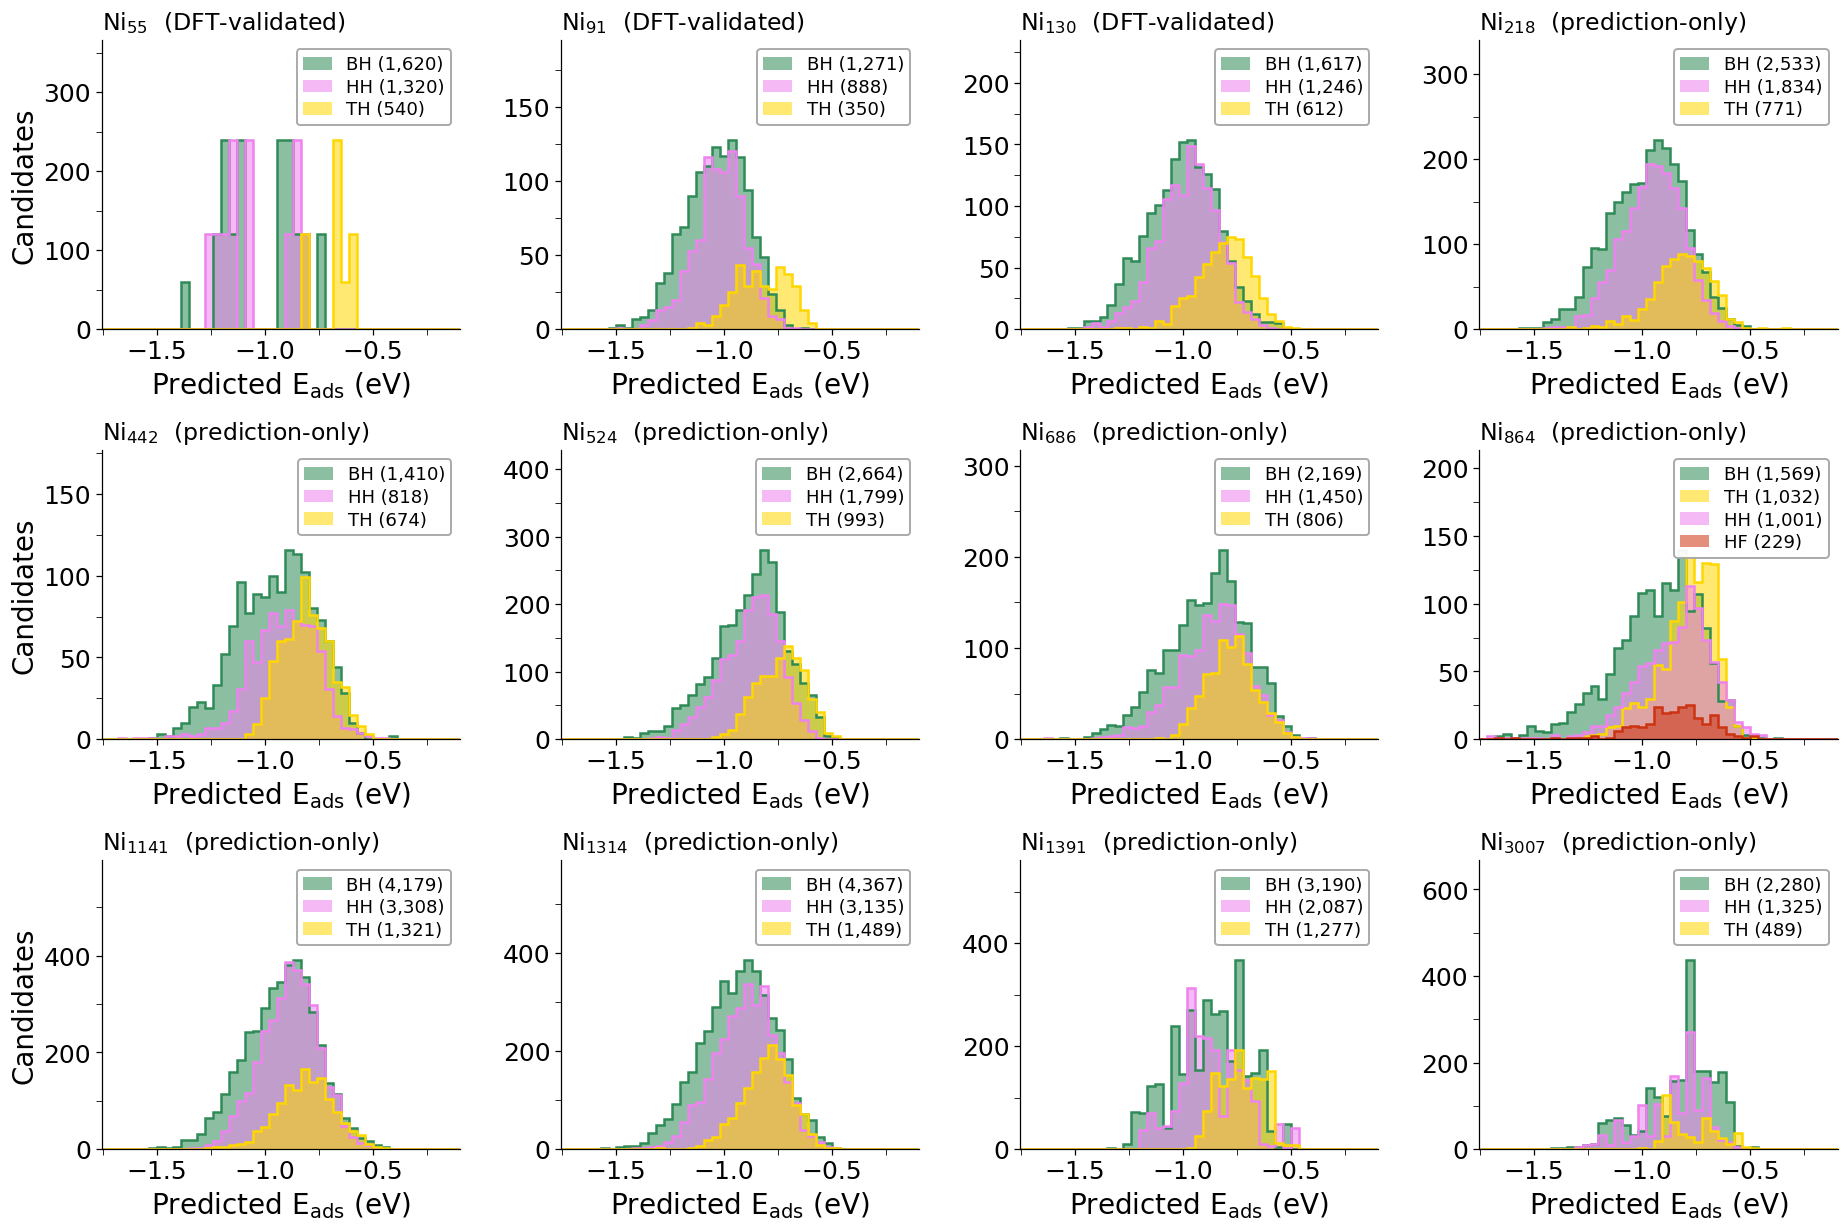

In [12]:
SI_LEGEND = {"fontsize": 13, "title_fontsize": 13, "framealpha": 0.95,
             "borderpad": 0.35, "labelspacing": 0.25, "handlelength": 1.6}


def particle_grid(n_panels: int, ncols: int = 4, width: float = 5.6, height: float = 4.8):
    nrows = int(np.ceil(n_panels / ncols))
    figure, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows), squeeze=False)
    axes = axes.ravel()
    for axis in axes[n_panels:]:
        axis.set_visible(False)
    return figure, axes[:n_panels]


def label_particle(axis, system: str) -> None:
    status = "DFT-validated" if retained[system]["dft_validated"].iloc[0] else "prediction-only"
    axis.set_title(f"{display_name(system)}  ({status})", loc="left",
                   fontsize=FONT["legend"] + 1, pad=8)


def si_subset() -> pd.DataFrame:
    return pd.concat([d[d["motif"].isin(si_motifs[s])] for s, d in retained.items()])


def make_si_histograms() -> None:
    energy_limits = padded_limits(si_subset()[ENERGY_COL].to_numpy(dtype=float), pad=0.03)
    bins = np.linspace(*energy_limits, 46)
    with plt.rc_context(STYLE_PAPER):
        fig, axes = particle_grid(len(retained))
        for index, (axis, (system, data)) in enumerate(zip(axes, retained.items())):
            for motif in si_motifs[system]:
                values = data.loc[data["motif"] == motif, ENERGY_COL].to_numpy(float)
                axis.hist(values, bins=bins, color=motif_color(motif), alpha=0.55,
                          label=f"{motif} ({len(values):,})")
                axis.hist(values, bins=bins, histtype="step", color=motif_color(motif), lw=1.8)
            axis.set_xlim(*energy_limits)
            axis.set_ylim(0, axis.get_ylim()[1] * 1.45)
            axis.set_xlabel(ENERGY_LABEL)
            if index % 4 == 0:
                axis.set_ylabel("Candidates")
            axis.legend(loc="upper right", **SI_LEGEND)
            label_particle(axis, system)
            add_minor_ticks(axis)
        fig.subplots_adjust(hspace=0.42, wspace=0.28)
        save(fig, HERE / "SI_retained_motif_histograms.pdf")


make_si_histograms()

Wrote SI_Eads_vs_GCN_O.pdf


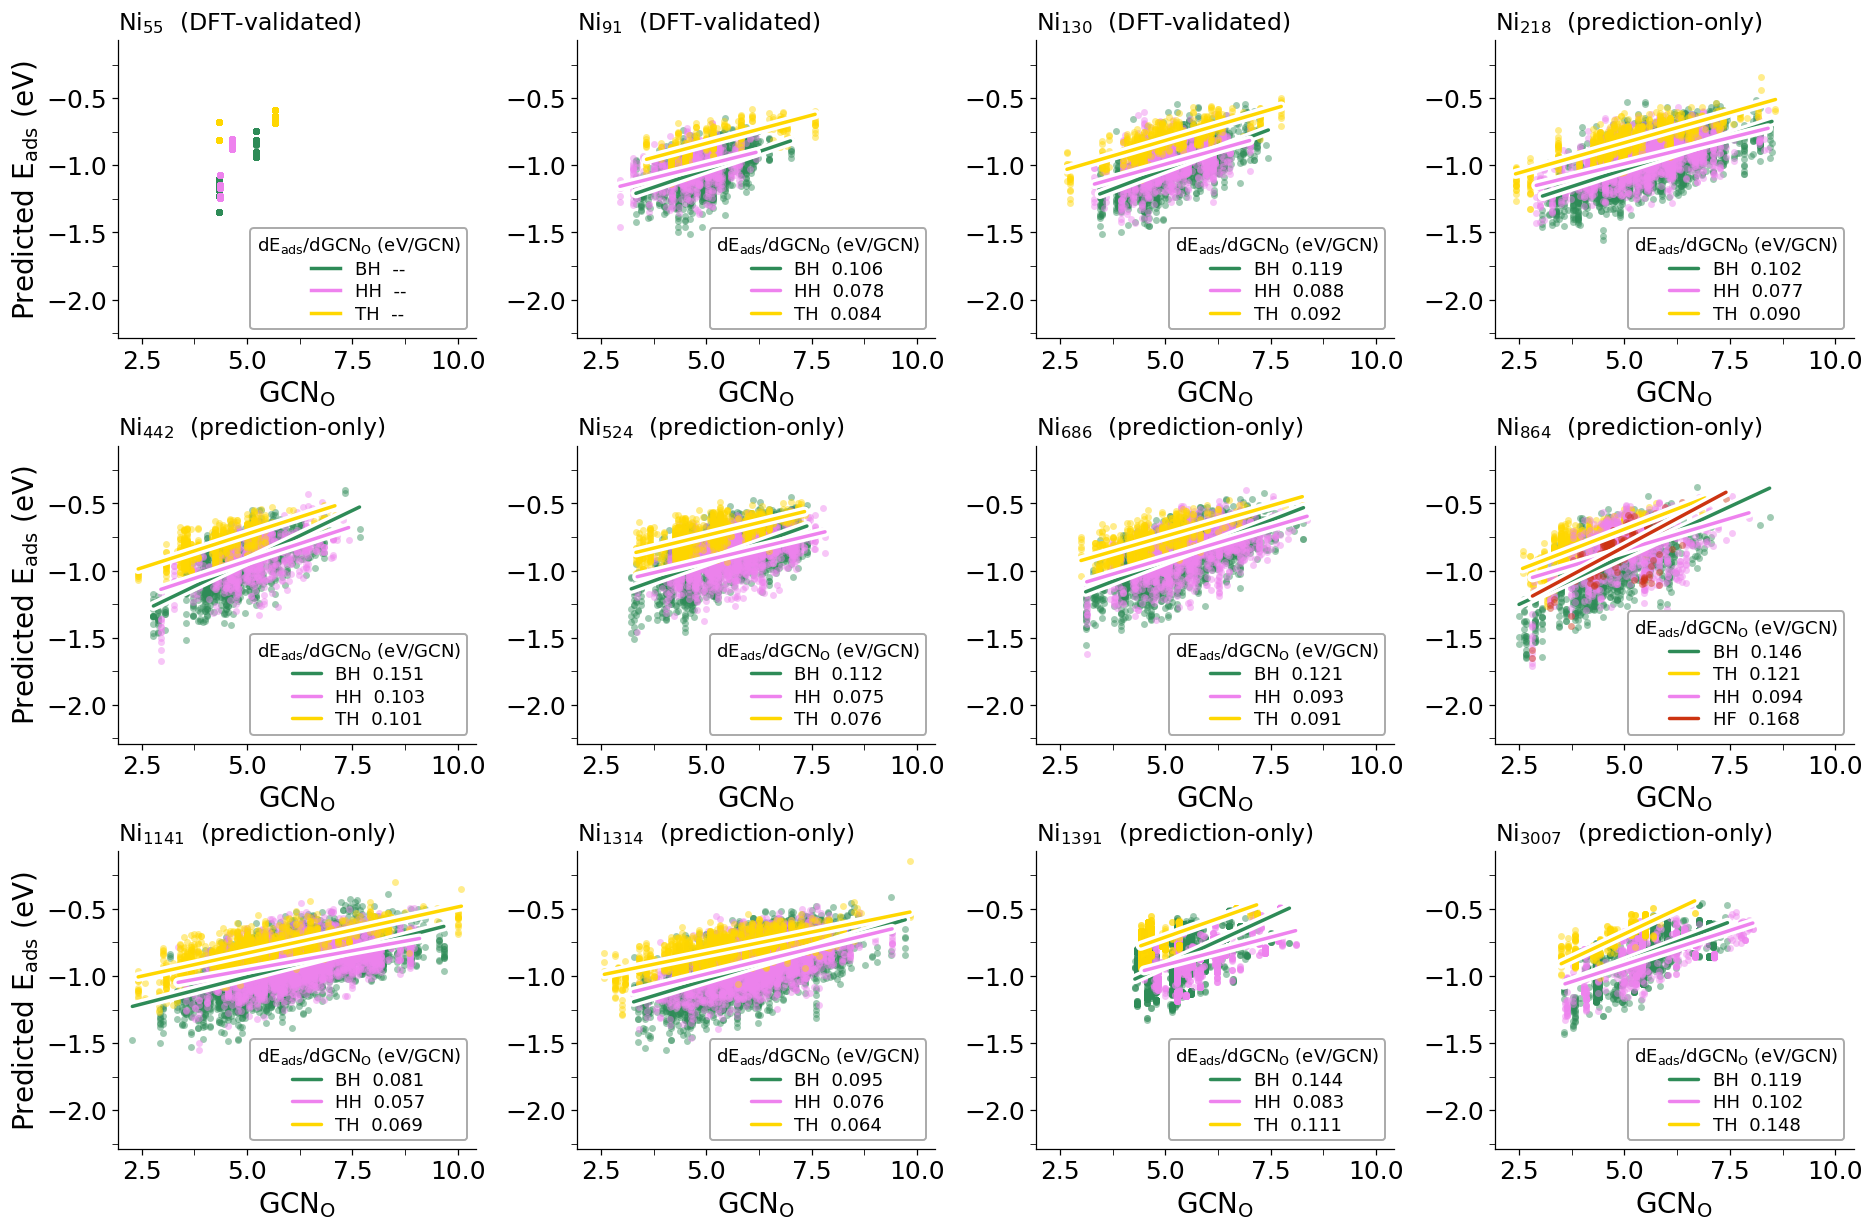

Wrote SI_Eads_vs_GCN_H.pdf


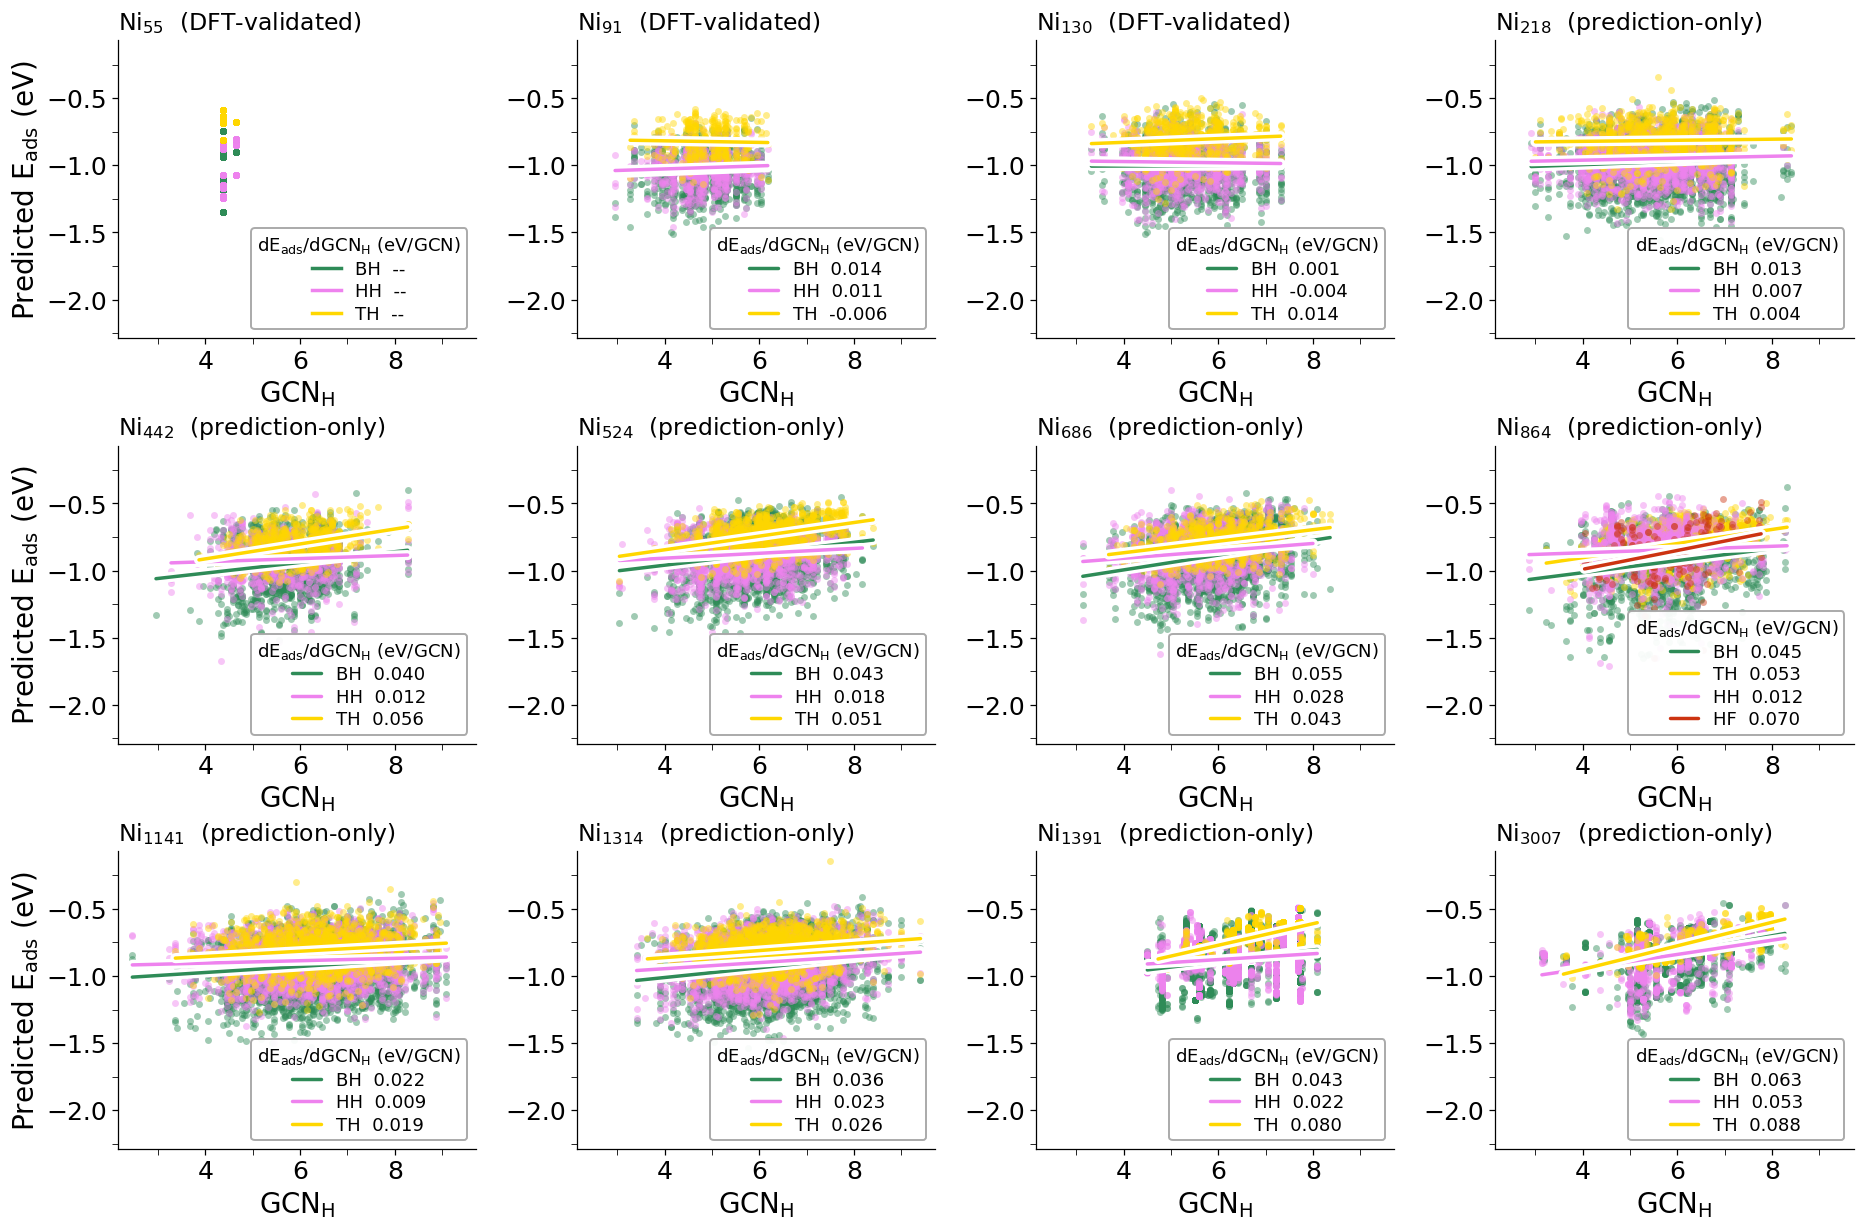

In [13]:
def make_si_scatter(descriptor: str, output: Path) -> None:
    shown = si_subset()
    energy_limits = padded_limits(shown[ENERGY_COL].to_numpy(dtype=float))
    span = energy_limits[1] - energy_limits[0]
    energy_limits = (energy_limits[0] - 0.30 * span, energy_limits[1])  # room for the legend
    gcn_limits = padded_limits(shown[descriptor].to_numpy(dtype=float))
    with plt.rc_context(STYLE_PAPER):
        fig, axes = particle_grid(len(retained))
        for index, (axis, (system, data)) in enumerate(zip(axes, retained.items())):
            scatter_with_fits(axis, data, si_motifs[system], descriptor)
            axis.set_xlim(*gcn_limits)
            axis.set_ylim(*energy_limits)
            axis.set_xlabel(GCN_LABEL[descriptor])
            if index % 4 == 0:
                axis.set_ylabel(ENERGY_LABEL)
            axis.legend(loc="lower right", title=slope_legend_title(descriptor), **SI_LEGEND)
            label_particle(axis, system)
            add_minor_ticks(axis)
        fig.subplots_adjust(hspace=0.36, wspace=0.28)
        save(fig, output)


make_si_scatter("o_site_gcn", HERE / "SI_Eads_vs_GCN_O.pdf")
make_si_scatter("h_site_gcn", HERE / "SI_Eads_vs_GCN_H.pdf")

## 6. $\mathrm{Ni}_{55}$ and $\mathrm{Ni}_{91}$ GCN panels (SI)

$\mathrm{E}_\mathrm{ads}$ vs $\mathrm{GCN}_\mathrm{O}$ (top) and $\mathrm{GCN}_\mathrm{H}$ (bottom) for the BH, HH and TH candidates on the two smaller
DFT-validated NPs.

Wrote GCN_Ni55_Ni91_SI.pdf


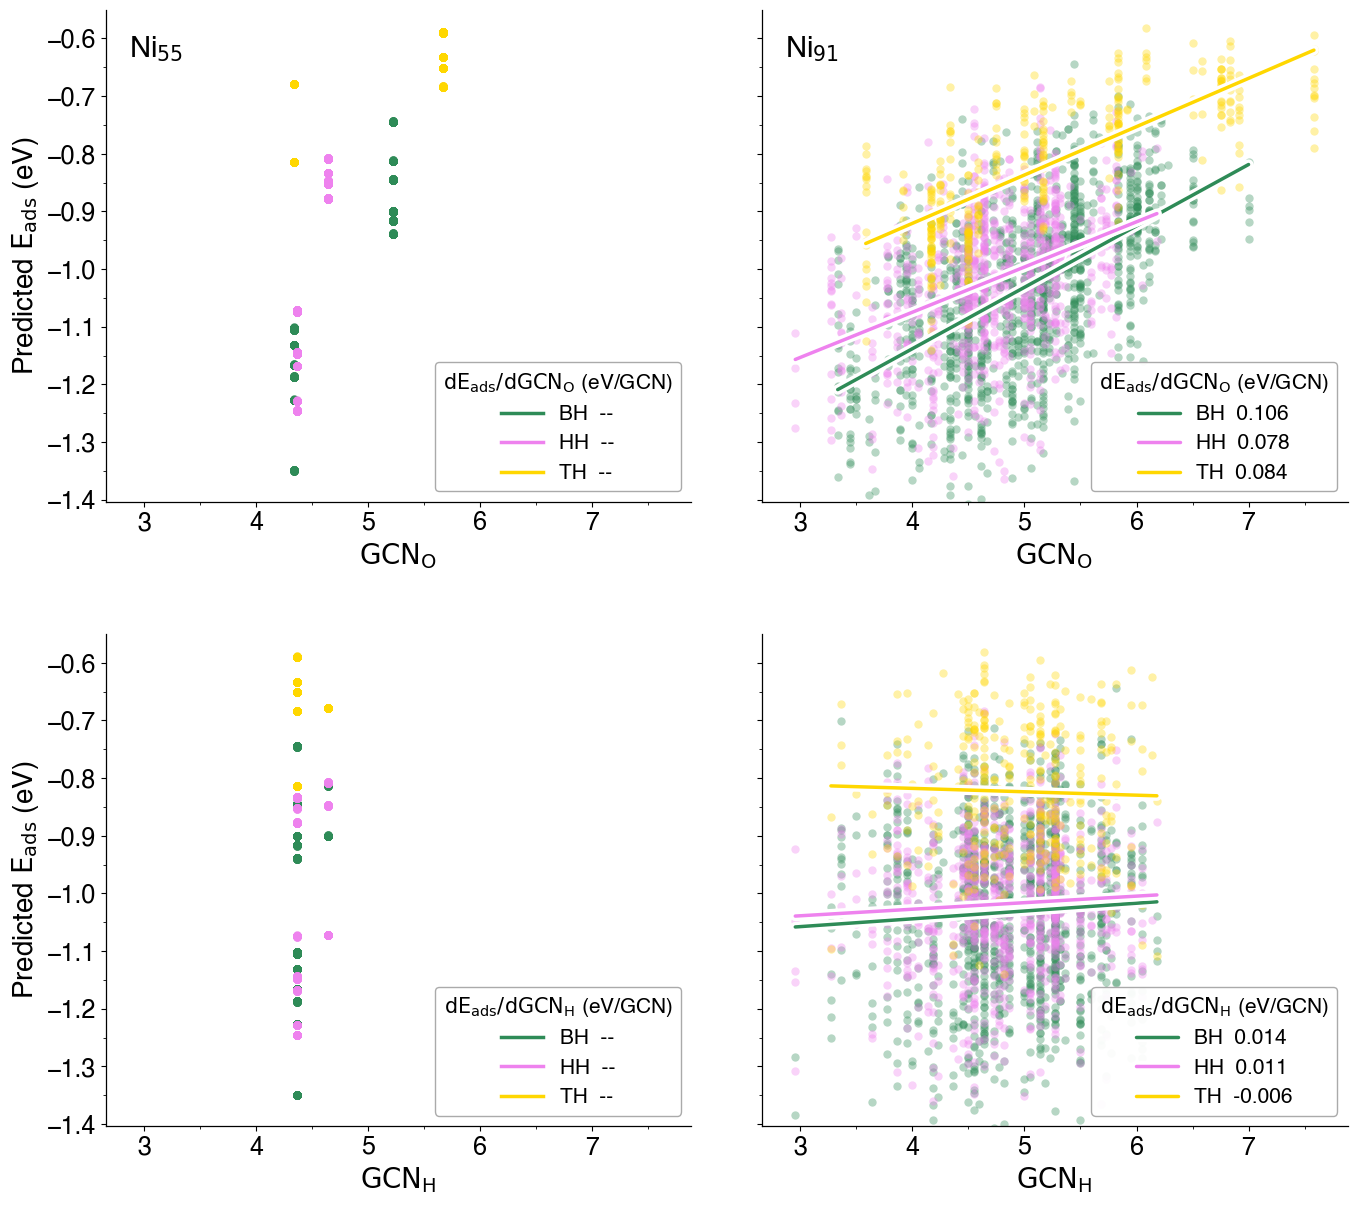

In [14]:
def make_gcn_ni55_ni91_si(systems=("Ni55", "Ni91")) -> None:
    data = pd.concat([retained[s][retained[s]["motif"].isin(MAIN_MOTIFS)] for s in systems],
                     ignore_index=True)
    energy = data[ENERGY_COL].to_numpy(dtype=float)
    energy_lo, energy_hi = np.nanpercentile(energy, [0.3, 99.7])
    energy_pad = 0.05 * (energy_hi - energy_lo)
    energy_limits = (energy_lo - energy_pad, energy_hi + energy_pad)
    gcn = np.concatenate([data["o_site_gcn"].to_numpy(float), data["h_site_gcn"].to_numpy(float)])
    gcn = gcn[np.isfinite(gcn)]
    gcn_limits = (float(gcn.min()) - 0.3, float(gcn.max()) + 0.3)

    with plt.rc_context(STYLE_GCN_SI):
        fig, axes = plt.subplots(2, 2, figsize=(13.8, 12.4))
        for row, descriptor in enumerate(("o_site_gcn", "h_site_gcn")):
            for column, system in enumerate(systems):
                axis = axes[row, column]
                scatter_with_fits(axis, data[data["system"] == system], MAIN_MOTIFS, descriptor,
                                  ms=12, alpha=0.35, min_points=0, n_fit=100)
                axis.set_xlim(*gcn_limits)
                axis.set_ylim(*energy_limits)
                axis.set_xlabel(GCN_LABEL[descriptor])
                if column == 0:
                    axis.set_ylabel(ENERGY_LABEL)
                else:
                    axis.tick_params(labelleft=False)
                if row == 0:
                    axis.text(0.04, 0.95, display_name(system), transform=axis.transAxes,
                              fontsize=21, fontweight="bold", va="top")
                axis.legend(loc="lower right", title=slope_legend_title(descriptor),
                            title_fontsize=15, framealpha=0.95)
                add_minor_ticks(axis, length=None)
        fig.subplots_adjust(left=0.085, right=0.985, bottom=0.075, top=0.975,
                            hspace=0.27, wspace=0.12)
        fig.align_ylabels(axes[:, 0])
        save(fig, HERE / "GCN_Ni55_Ni91_SI.pdf")


make_gcn_ni55_ni91_si()

## 7. Separability of $\mathrm{GCN}_\mathrm{O}$ and $\mathrm{GCN}_\mathrm{H}$ on $\mathrm{Ni}_{91}$ and $\mathrm{Ni}_{130}$ (Figure S12)

(a) Per-NP coefficients of the centred bilinear model
$\mathrm{E_{ads}} = \alpha_m + \beta_\mathrm{O}\widetilde{\mathrm{GCN}}_\mathrm{O} + \beta_\mathrm{H}\widetilde{\mathrm{GCN}}_\mathrm{H} + \gamma\,\widetilde{\mathrm{GCN}}_\mathrm{O}\widetilde{\mathrm{GCN}}_\mathrm{H}$
(motif intercepts $\alpha_m$, mean-centred GCNs, 95% confidence intervals).

(b) Held-out unique (semipartial) $R^2$ of each structural term: $R^2$(full) − $R^2$(full without the term),
averaged over 15 random 75/25 splits. Every term enters as a binned categorical.

In [15]:
S12_SYSTEMS = ["Ni91", "Ni130"]
S12_COLORS = {"Ni91": "darkorange", "Ni130": "darkviolet"}
S12_TERMS = [
    ("o_site_gcn_c", "$\\beta_\\mathrm{O}$\n" + r"($\mathrm{GCN}_\mathrm{O}$)"),
    ("h_site_gcn_c", "$\\beta_\\mathrm{H}$\n" + r"($\mathrm{GCN}_\mathrm{H}$)"),
    ("o_site_gcn_c:h_site_gcn_c",
     "$\\gamma$\n" + r"($\mathrm{GCN}_\mathrm{O}\!\times\!\mathrm{GCN}_\mathrm{H}$)"),
]
S12_EQUATION = (r"$\mathrm{E}_\mathrm{ads} = \alpha_m"
                r" + \beta_\mathrm{O}\,\widetilde{\mathrm{GCN}}_\mathrm{O}"
                r" + \beta_\mathrm{H}\,\widetilde{\mathrm{GCN}}_\mathrm{H}"
                r" + \gamma\,\widetilde{\mathrm{GCN}}_\mathrm{O}\widetilde{\mathrm{GCN}}_\mathrm{H}$")
R2_LABELS = {"motif": "motif", "O-site GCN": r"$\mathrm{GCN}_\mathrm{O}$",
             "H-site GCN": r"$\mathrm{GCN}_\mathrm{H}$", "site distance": r"$d_\mathrm{site-site}$",
             "particle identity": "particle\nidentity"}
R2_ACCENT = {"O-site GCN", "H-site GCN"}
GCN_BIN_EDGES = np.arange(2, 11, 1)
SITE_DISTANCE_BIN_EDGES = [0, 2.5, 3, 3.5, 4, 4.5, 5.01]
N_SPLITS = 15


def bilinear_coefficients(data: pd.DataFrame):
    """OLS of Eads ~ C(motif) + GCN_O_c + GCN_H_c + GCN_O_c:GCN_H_c."""
    o_c = (data["o_site_gcn"] - data["o_site_gcn"].mean()).to_numpy()
    h_c = (data["h_site_gcn"] - data["h_site_gcn"].mean()).to_numpy()
    design_frame = pd.concat([
        pd.DataFrame({"Intercept": np.ones(len(data))}),
        pd.get_dummies(data["motif"].astype(str), prefix="motif", drop_first=True,
                       dtype=float).reset_index(drop=True),
    ], axis=1)
    design_frame["o_site_gcn_c"] = o_c
    design_frame["h_site_gcn_c"] = h_c
    design_frame["o_site_gcn_c:h_site_gcn_c"] = o_c * h_c
    design = design_frame.to_numpy(dtype=float)
    energy = data[ENERGY_COL].to_numpy(dtype=float)
    coefficients, *_ = np.linalg.lstsq(design, energy, rcond=None)
    residual = energy - design @ coefficients
    dof = len(energy) - int(np.linalg.matrix_rank(design))
    covariance = float(residual @ residual) / dof * np.linalg.pinv(design.T @ design)
    se = np.sqrt(np.diag(covariance))
    critical = float(student_t.ppf(0.975, dof))
    table = pd.DataFrame({
        "term": design_frame.columns, "coefficient": coefficients,
        "p_value": 2.0 * student_t.sf(np.abs(coefficients / se), dof),
        "ci_low": coefficients - critical * se, "ci_high": coefficients + critical * se,
    }).set_index("term")
    r_squared = 1.0 - float(residual @ residual) / float(np.sum((energy - energy.mean()) ** 2))
    return table, r_squared, len(energy)


def bin_labels(values, edges) -> pd.Series:
    values = pd.Series(np.asarray(values, dtype=float))
    low, high = float(edges[0]), float(edges[-1])
    epsilon = 1.0e-9 * max(1.0, high - low)
    labels = pd.cut(values.clip(low + epsilon, high - epsilon), edges).astype(str)
    if (labels == "nan").any():
        raise ValueError("Descriptor binning produced an invalid category")
    return labels


def term_matrix(data: pd.DataFrame, column: str) -> np.ndarray:
    codes = data[column].astype("category").cat.codes.to_numpy()
    return np.column_stack([(codes == level).astype(float) for level in np.unique(codes)[1:]])


def held_out_r2(train_x, train_y, test_x, test_y) -> float:
    train_design = np.column_stack([train_x, np.ones(len(train_y))]) if train_x.size else np.ones((len(train_y), 1))
    test_design = np.column_stack([test_x, np.ones(len(test_y))]) if test_x.size else np.ones((len(test_y), 1))
    coefficients, *_ = np.linalg.lstsq(train_design, train_y, rcond=None)
    prediction = test_design @ coefficients
    return float(1.0 - np.sum((test_y - prediction) ** 2) / np.sum((test_y - test_y.mean()) ** 2))


def unique_r2(data: pd.DataFrame, first_seed: int = 0) -> pd.DataFrame:
    sample = data.dropna(subset=[ENERGY_COL, "o_site_gcn", "h_site_gcn", "site_distance_A",
                                 "motif", "n_atoms"]).copy()
    sample["o_gcn_bin"] = bin_labels(sample["o_site_gcn"], GCN_BIN_EDGES).values
    sample["h_gcn_bin"] = bin_labels(sample["h_site_gcn"], GCN_BIN_EDGES).values
    sample["distance_bin"] = bin_labels(sample["site_distance_A"], SITE_DISTANCE_BIN_EDGES).values
    sample["motif_label"] = sample["motif"].astype(str)
    sample["particle_label"] = sample["n_atoms"].astype(str)
    term_columns = {"motif": "motif_label", "O-site GCN": "o_gcn_bin", "H-site GCN": "h_gcn_bin",
                    "site distance": "distance_bin", "particle identity": "particle_label"}
    order = list(term_columns)
    blocks = {term: term_matrix(sample, column) for term, column in term_columns.items()}
    energy = sample[ENERGY_COL].to_numpy(dtype=float)

    records = []
    for seed in range(first_seed, first_seed + N_SPLITS):
        test = np.random.default_rng(seed).random(len(energy)) < 0.25
        train = ~test

        def model_r2(terms):
            if not terms:
                return 0.0
            design = np.column_stack([blocks[term] for term in terms])
            return held_out_r2(design[train], energy[train], design[test], energy[test])

        full = model_r2(order)
        for term in order:
            records.append({"seed": seed, "term": term, "full_r2": full,
                            "unique_r2": full - model_r2([o for o in order if o != term])})
    raw = pd.DataFrame(records)
    summary = (raw.groupby("term", sort=False)["unique_r2"]
               .agg(unique_r2="mean", unique_r2_sd="std").loc[order].reset_index())
    summary.attrs["full_r2"] = float(raw.groupby("seed")["full_r2"].first().mean())
    return summary

Analysis scope: 5,984 retained BH/HH/TH candidates

Ni91: n=2,509, model R^2=0.456, r(GCN_O, GCN_H)=-0.066
  o_site_gcn_c                 +0.0948; 95% CI [+0.0890, +0.1006]; p=3.88e-191
  h_site_gcn_c                 +0.0200; 95% CI [+0.0125, +0.0275]; p=1.8e-07
  o_site_gcn_c:h_site_gcn_c    -0.0044; 95% CI [-0.0144, +0.0055]; p=0.384

Ni130: n=3,475, model R^2=0.500, r(GCN_O, GCN_H)=-0.052
  o_site_gcn_c                 +0.1045; 95% CI [+0.1001, +0.1089]; p=0
  h_site_gcn_c                 +0.0080; 95% CI [+0.0028, +0.0132]; p=0.00239
  o_site_gcn_c:h_site_gcn_c    +0.0120; 95% CI [+0.0058, +0.0181]; p=0.000134

Mean held-out full-model R^2: 0.491
             term  unique_r2  unique_r2_sd
            motif     0.1979        0.0100
       O-site GCN     0.2467        0.0119
       H-site GCN     0.0075        0.0021
    site distance     0.0381        0.0048
particle identity    -0.0003        0.0007
Wrote SI_gcn_separability_DFT.pdf


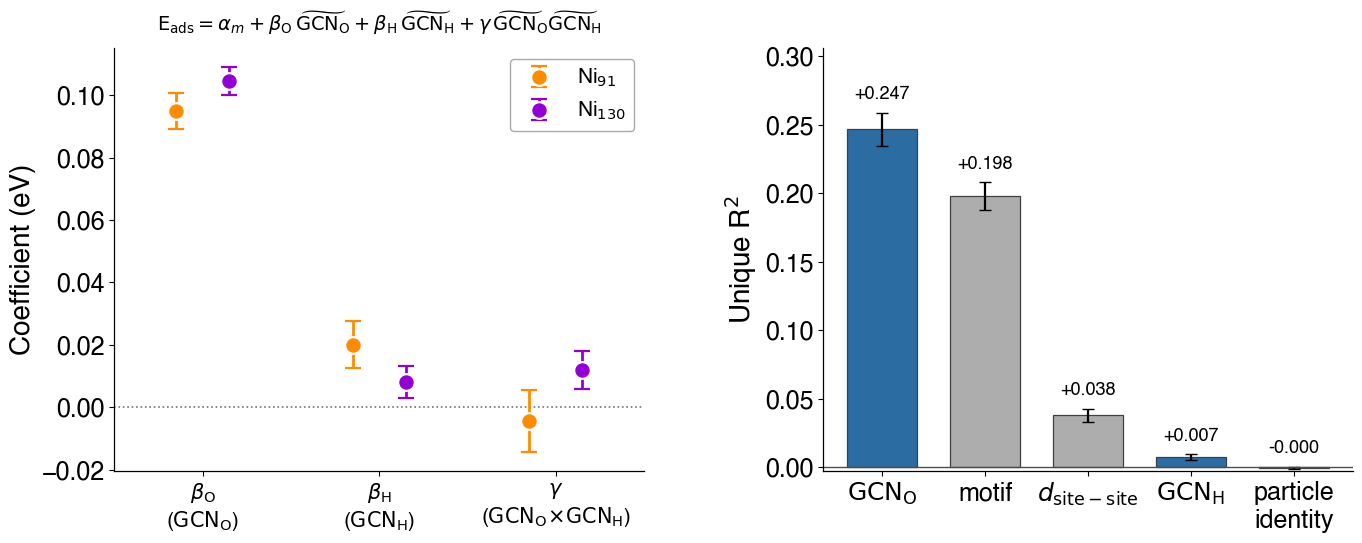

In [16]:
def make_figure_s12() -> None:
    data = pd.concat([retained[s][retained[s]["motif"].isin(MAIN_MOTIFS)] for s in S12_SYSTEMS],
                     ignore_index=True)
    print(f"Analysis scope: {len(data):,} retained BH/HH/TH candidates")
    coefficient_tables = {}
    for system in S12_SYSTEMS:
        subset = data[data["system"] == system].reset_index(drop=True)
        table, model_r2, n_points = bilinear_coefficients(subset)
        coefficient_tables[system] = table
        print(f"\n{system}: n={n_points:,}, model R^2={model_r2:.3f}, "
              f"r(GCN_O, GCN_H)={subset['o_site_gcn'].corr(subset['h_site_gcn']):+.3f}")
        for term, _ in S12_TERMS:
            row = table.loc[term]
            print(f"  {term:<28} {row['coefficient']:+.4f}; 95% CI [{row['ci_low']:+.4f}, "
                  f"{row['ci_high']:+.4f}]; p={row['p_value']:.3g}")
    r2 = unique_r2(data)
    print(f"\nMean held-out full-model R^2: {r2.attrs['full_r2']:.3f}")
    print(r2.to_string(index=False, float_format=lambda value: f"{value:.4f}"))

    with plt.rc_context(STYLE_GCN_SI):
        fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.8))
        axis = axes[0]
        offsets = {S12_SYSTEMS[0]: -0.15, S12_SYSTEMS[1]: 0.15}
        for system in S12_SYSTEMS:
            table = coefficient_tables[system]
            y = [table.loc[term, "coefficient"] for term, _ in S12_TERMS]
            lower = [table.loc[t, "coefficient"] - table.loc[t, "ci_low"] for t, _ in S12_TERMS]
            upper = [table.loc[t, "ci_high"] - table.loc[t, "coefficient"] for t, _ in S12_TERMS]
            axis.errorbar([i + offsets[system] for i in range(len(S12_TERMS))], y,
                          yerr=[lower, upper], fmt="o", ms=12, lw=0, elinewidth=2.0, capsize=6,
                          capthick=2.0, color=S12_COLORS[system], markeredgecolor="white",
                          markeredgewidth=1.6, label=display_name(system), zorder=3)
        axis.axhline(0, color="0.45", lw=1.2, ls=":", zorder=1)
        axis.set_xticks(range(len(S12_TERMS)))
        axis.set_xticklabels([label for _, label in S12_TERMS], fontsize=15)
        axis.set_xlim(-0.5, len(S12_TERMS) - 0.5)
        axis.set_ylabel("Coefficient (eV)")
        axis.set_title(S12_EQUATION, fontsize=14, pad=12)
        axis.legend(loc="upper right", framealpha=0.95)

        axis = axes[1]
        ordered = r2.sort_values("unique_r2", ascending=False)
        x = np.arange(len(ordered))
        axis.bar(x, ordered["unique_r2"], yerr=ordered["unique_r2_sd"],
                 color=["#2b6ca3" if t in R2_ACCENT else "0.68" for t in ordered["term"]],
                 edgecolor="0.25", linewidth=0.9, width=0.68,
                 error_kw={"elinewidth": 1.6, "capsize": 4})
        maximum = float(ordered["unique_r2"].max())
        minimum = float(min(0.0, ordered["unique_r2"].min()))
        for position, value, uncertainty in zip(x, ordered["unique_r2"], ordered["unique_r2_sd"]):
            axis.text(position, max(value + uncertainty, 0.0) + 0.028 * maximum, f"{value:+.3f}",
                      ha="center", va="bottom", fontsize=13)
        axis.axhline(0, color="0.3", lw=1.0, zorder=2)
        axis.set_xticks(x)
        axis.set_xticklabels([R2_LABELS[t] for t in ordered["term"]])
        axis.set_ylabel(r"Unique R$^2$")
        axis.set_ylim(min(minimum * 3.0, -0.012 * maximum), maximum * 1.24)
        fig.tight_layout(w_pad=3.0)
        save(fig, HERE / "SI_gcn_separability_DFT.pdf")


make_figure_s12()

## 8. $\mathrm{GCN}_\mathrm{O}$ vs $\mathrm{GCN}_\mathrm{H}$ across all NPs (robustness check, not in the paper)

Checks that the $\mathrm{GCN}_\mathrm{O}$ dominance of section 7 holds on every NP, with two models.

- **Per motif:** $\mathrm{E_{ads}} = a + \beta_\mathrm{O}\mathrm{GCN_O} + \beta_\mathrm{H}\mathrm{GCN_H}$, fitted to each NP and motif separately, with HC3
  standard errors. The output includes $\beta_\mathrm{O} - \beta_\mathrm{H}$ with its SE (covariance included), partial $R^2$ (share of the
  one-descriptor model's residual variance removed by adding the other descriptor), and effects per standard deviation of each GCN.
- **All motifs together:** the section 7 (Figure S12) model fitted to each NP,
  $\mathrm{E_{ads}} = \alpha_m + \beta_\mathrm{O}\widetilde{\mathrm{GCN}}_\mathrm{O} + \beta_\mathrm{H}\widetilde{\mathrm{GCN}}_\mathrm{H} + \gamma\,\widetilde{\mathrm{GCN}}_\mathrm{O}\widetilde{\mathrm{GCN}}_\mathrm{H}$
  (BH, HH and TH pooled with motif intercepts, mean-centred GCNs, classical 95% confidence intervals).
  For $\mathrm{Ni}_{91}$ and $\mathrm{Ni}_{130}$ it gives exactly the Figure S12 coefficients.

Across NPs (per-motif model): paired tests with NPs as replicates, and a pooled within-group fit
(fixed effect per NP × motif, CR1 standard errors clustered by NP, t on $\mathrm{n}_\mathrm{NP}$ − 1 df).
A fit needs ≥ 30 candidates and ≥ 10 distinct values of both GCNs, so $\mathrm{Ni}_{55}$ drops out of both models.

In [17]:
def joint_eligible(data: pd.DataFrame) -> bool:
    return (len(data) >= MIN_POINTS_FOR_SLOPE
            and data["o_site_gcn"].nunique() >= MIN_GCN_UNIQUE_FOR_SLOPE
            and data["h_site_gcn"].nunique() >= MIN_GCN_UNIQUE_FOR_SLOPE)


def ssr(X, y) -> float:
    return float(np.sum(ols(X, y)[1] ** 2))


def joint_fit(data: pd.DataFrame) -> dict:
    y = data[ENERGY_COL].to_numpy(float)
    x_o, x_h = data["o_site_gcn"].to_numpy(float), data["h_site_gcn"].to_numpy(float)
    simple_o, simple_h = ols_slope(x_o, y), ols_slope(x_h, y)
    ones = np.ones_like(y)
    design = np.column_stack([ones, x_o, x_h])
    params, residual, xtx_inv = ols(design, y)
    cov = hc3_cov(design, residual, xtx_inv)
    beta_o, beta_h = params[1], params[2]
    se_o, se_h = np.sqrt(cov[1, 1]), np.sqrt(cov[2, 2])
    delta_se = float(np.sqrt(cov[1, 1] + cov[2, 2] - 2.0 * cov[1, 2]))
    p_two_sided = lambda value, se: float(2.0 * norm.sf(abs(value / se)))
    ssr_full = float(np.sum(residual**2))
    ssr_only_o = ssr(np.column_stack([ones, x_o]), y)
    ssr_only_h = ssr(np.column_stack([ones, x_h]), y)
    return {
        "n": len(y), "r_gcnO_gcnH": float(np.corrcoef(x_o, x_h)[0, 1]),
        "beta_O_simple": simple_o[0], "beta_O_simple_se": simple_o[2],
        "beta_H_simple": simple_h[0], "beta_H_simple_se": simple_h[2],
        "beta_O": beta_o, "beta_O_se": se_o, "beta_O_p": p_two_sided(beta_o, se_o),
        "beta_H": beta_h, "beta_H_se": se_h, "beta_H_p": p_two_sided(beta_h, se_h),
        "delta": beta_o - beta_h, "delta_se": delta_se,
        "delta_p": p_two_sided(beta_o - beta_h, delta_se),
        "partial_r2_O": (ssr_only_h - ssr_full) / ssr_only_h,
        "partial_r2_H": (ssr_only_o - ssr_full) / ssr_only_o,
        "r2_joint": 1.0 - ssr_full / float(np.sum((y - y.mean()) ** 2)),
        "sd_gcnO": float(x_o.std(ddof=1)), "sd_gcnH": float(x_h.std(ddof=1)),
        "effect_O_per_sd_eV": beta_o * x_o.std(ddof=1),
        "effect_H_per_sd_eV": beta_h * x_h.std(ddof=1),
    }


joint_rows = []
for system, data in retained.items():
    for motif in MAIN_MOTIFS:
        group = data[data["motif"] == motif].dropna(subset=["o_site_gcn", "h_site_gcn", ENERGY_COL])
        record = {"system": system, "n_atoms": n_atoms(system),
                  "dft_validated": bool(data["dft_validated"].iloc[0]), "motif": motif,
                  "usable": joint_eligible(group)}
        record |= joint_fit(group) if record["usable"] else {"n": len(group)}
        joint_rows.append(record)
joint = pd.DataFrame(joint_rows)
joint.to_csv(HERE / "gcn_O_vs_H_slopes_per_particle.csv", index=False)
skipped = joint[~joint["usable"]]
print("Not fitted: " + ", ".join(f"{r.system} {r.motif}" for r in skipped.itertuples()))

columns = {"system": "system", "n": "n", "r_gcnO_gcnH": "r(O,H)", "beta_O": "β_O", "beta_O_se": "±",
           "beta_H": "β_H", "beta_H_se": "± ", "beta_H_p": "p(β_H)", "delta": "β_O-β_H",
           "delta_se": "±  ", "partial_r2_O": "pR2_O", "partial_r2_H": "pR2_H",
           "effect_O_per_sd_eV": "O/SD(eV)", "effect_H_per_sd_eV": "H/SD(eV)"}
print("\nPer motif: E = a + β_O*GCN_O + β_H*GCN_H (HC3 SE; eV/GCN)")
for motif in MAIN_MOTIFS:
    part = joint[joint["usable"] & (joint["motif"] == motif)].sort_values("n_atoms")
    print(f"\n{motif}")
    print(part[list(columns)].rename(columns=columns)
          .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Not fitted: Ni55 BH, Ni55 HH, Ni55 TH

Per motif: E = a + β_O*GCN_O + β_H*GCN_H (HC3 SE; eV/GCN)

BH
system    n  r(O,H)   β_O     ±    β_H    ±   p(β_H)  β_O-β_H   ±    pR2_O  pR2_H  O/SD(eV)  H/SD(eV)
  Ni91 1271  -0.052 0.107 0.004  0.021 0.006   0.001    0.087 0.007  0.307  0.010     0.078     0.012
 Ni130 1617  -0.031 0.119 0.003  0.006 0.004   0.163    0.113 0.005  0.416  0.001     0.104     0.004
 Ni218 2533   0.139 0.103 0.002 -0.003 0.003   0.268    0.106 0.004  0.405  0.000     0.109    -0.003
 Ni442 1410   0.028 0.150 0.004  0.035 0.005   0.000    0.115 0.006  0.448  0.036     0.119     0.026
 Ni524 2664   0.064 0.110 0.003  0.035 0.003   0.000    0.076 0.004  0.409  0.053     0.103     0.029
 Ni686 2169   0.120 0.117 0.003  0.039 0.003   0.000    0.079 0.004  0.450  0.060     0.118     0.033
 Ni864 1569   0.176 0.142 0.005  0.021 0.005   0.000    0.121 0.007  0.369  0.014     0.123     0.019
Ni1141 4179   0.166 0.080 0.002  0.007 0.002   0.001    0.073 0.003  0.350  0.003  

In [18]:
across_rows = []
usable = joint[joint["usable"]]
for motif in MAIN_MOTIFS + ["all"]:
    subset = usable if motif == "all" else usable[usable["motif"] == motif]
    beta_o, beta_h = subset["beta_O"].to_numpy(float), subset["beta_H"].to_numpy(float)

    # Pooled within-group fit: fixed effect per NP x motif absorbed by demeaning.
    frames = [retained[s][retained[s]["motif"].isin(subset.loc[subset["system"] == s, "motif"])]
              for s in subset["system"].unique()]
    data = pd.concat(frames).dropna(subset=["o_site_gcn", "h_site_gcn"])
    group = data["system"] + "_" + data["motif"]
    cols = [ENERGY_COL, "o_site_gcn", "h_site_gcn"]
    within = data[cols] - data[cols].groupby(group).transform("mean")
    X = within[["o_site_gcn", "h_site_gcn"]].to_numpy(float)
    y = within[ENERGY_COL].to_numpy(float)
    params, residual, xtx_inv = ols(X, y)
    clusters = data["system"].to_numpy()
    n_clusters = len(np.unique(clusters))
    cov = cluster_cov(X, residual, xtx_inv, clusters, n_params=2 + group.nunique())
    se = np.sqrt(np.diag(cov))
    delta_se = np.sqrt(cov[0, 0] + cov[1, 1] - 2.0 * cov[0, 1])
    p_cluster = lambda value, err: float(2.0 * student_t.sf(abs(value / err), df=n_clusters - 1))

    across_rows.append({
        "motif": motif, "n_fits": len(subset), "n_particles": subset["system"].nunique(),
        "beta_O_mean": beta_o.mean(), "beta_O_sd": beta_o.std(ddof=1),
        "beta_O_min": beta_o.min(), "beta_O_max": beta_o.max(),
        "beta_H_mean": beta_h.mean(), "beta_H_sd": beta_h.std(ddof=1),
        "beta_H_min": beta_h.min(), "beta_H_max": beta_h.max(),
        "n_betaO_gt_betaH": int((beta_o > beta_h).sum()),
        "n_delta_significant": int(((subset["delta"] > 0) & (subset["delta_p"] < 0.05)).sum()),
        "n_betaH_significant": int((subset["beta_H_p"] < 0.05).sum()),
        "paired_t_p": float(ttest_rel(beta_o, beta_h).pvalue),
        "wilcoxon_p": float(wilcoxon(beta_o, beta_h).pvalue),
        "partial_r2_O_median": float(subset["partial_r2_O"].median()),
        "partial_r2_H_median": float(subset["partial_r2_H"].median()),
        "effect_O_per_sd_median_eV": float(subset["effect_O_per_sd_eV"].median()),
        "effect_H_per_sd_median_eV": float(subset["effect_H_per_sd_eV"].median()),
        "pooled_beta_O": params[0], "pooled_beta_O_se": se[0],
        "pooled_beta_H": params[1], "pooled_beta_H_se": se[1],
        "pooled_beta_H_p": p_cluster(params[1], se[1]),
        "pooled_delta_p": p_cluster(params[0] - params[1], delta_se),
        "pooled_n": len(y),
    })
across = pd.DataFrame(across_rows)
across.to_csv(HERE / "gcn_O_vs_H_slopes_across_particles.csv", index=False)

for row in across.itertuples():
    print(f"\n{row.motif}: {row.n_fits} fits over {row.n_particles} particles\n"
          f"  β_O  mean {row.beta_O_mean:.3f} ± {row.beta_O_sd:.3f} (SD)  "
          f"range [{row.beta_O_min:.3f}, {row.beta_O_max:.3f}]\n"
          f"  β_H  mean {row.beta_H_mean:+.3f} ± {row.beta_H_sd:.3f} (SD)  "
          f"range [{row.beta_H_min:+.3f}, {row.beta_H_max:+.3f}]\n"
          f"  β_O > β_H in {row.n_betaO_gt_betaH}/{row.n_fits} fits ({row.n_delta_significant} with p < 0.05); "
          f"β_H significant in {row.n_betaH_significant}/{row.n_fits}\n"
          f"  paired t p = {row.paired_t_p:.2g}, Wilcoxon p = {row.wilcoxon_p:.2g}\n"
          f"  median partial R2: GCN_O {row.partial_r2_O_median:.3f}, GCN_H {row.partial_r2_H_median:.3f}\n"
          f"  median effect per SD: GCN_O {row.effect_O_per_sd_median_eV:+.3f} eV, "
          f"GCN_H {row.effect_H_per_sd_median_eV:+.3f} eV\n"
          f"  pooled: β_O {row.pooled_beta_O:.3f} ± {row.pooled_beta_O_se:.3f}, "
          f"β_H {row.pooled_beta_H:+.3f} ± {row.pooled_beta_H_se:.3f} (p = {row.pooled_beta_H_p:.2g}); "
          f"β_O - β_H p = {row.pooled_delta_p:.2g} (n = {row.pooled_n:,})")


BH: 11 fits over 11 particles
  β_O  mean 0.115 ± 0.021 (SD)  range [0.080, 0.150]
  β_H  mean +0.022 ± 0.015 (SD)  range [-0.003, +0.043]
  β_O > β_H in 11/11 fits (11 with p < 0.05); β_H significant in 9/11
  paired t p = 2.4e-08, Wilcoxon p = 0.00098
  median partial R2: GCN_O 0.405, GCN_H 0.014
  median effect per SD: GCN_O +0.103 eV, GCN_H +0.019 eV
  pooled: β_O 0.103 ± 0.007, β_H +0.019 ± 0.005 (p = 0.0037); β_O - β_H p = 2.1e-08 (n = 27,249)

HH: 11 fits over 11 particles
  β_O  mean 0.085 ± 0.014 (SD)  range [0.057, 0.108]
  β_H  mean +0.016 ± 0.014 (SD)  range [-0.008, +0.033]
  β_O > β_H in 11/11 fits (11 with p < 0.05); β_H significant in 9/11
  paired t p = 3.4e-09, Wilcoxon p = 0.00098
  median partial R2: GCN_O 0.234, GCN_H 0.008
  median effect per SD: GCN_O +0.073 eV, GCN_H +0.012 eV
  pooled: β_O 0.077 ± 0.006, β_H +0.012 ± 0.005 (p = 0.038); β_O - β_H p = 1.9e-08 (n = 18,891)

TH: 11 fits over 11 particles
  β_O  mean 0.088 ± 0.017 (SD)  range [0.062, 0.114]
  β_H  

In [19]:
# All motifs together: the section 7 (Figure S12) bilinear model fitted to each NP.
all_motif_rows = []
for system, data in retained.items():
    sample = (data[data["motif"].isin(MAIN_MOTIFS)]
              .dropna(subset=["o_site_gcn", "h_site_gcn", ENERGY_COL]).reset_index(drop=True))
    if not joint_eligible(sample):
        print(f"Not fitted: {system} (too few distinct GCN values)")
        continue
    table, r_squared, n_points = bilinear_coefficients(sample)
    record = {"system": system, "n_atoms": n_atoms(system),
              "dft_validated": bool(data["dft_validated"].iloc[0]), "n": n_points, "r2": r_squared}
    for key, term in (("beta_O", "o_site_gcn_c"), ("beta_H", "h_site_gcn_c"),
                      ("gamma", "o_site_gcn_c:h_site_gcn_c")):
        record |= {key: table.loc[term, "coefficient"], f"{key}_ci_low": table.loc[term, "ci_low"],
                   f"{key}_ci_high": table.loc[term, "ci_high"], f"{key}_p": table.loc[term, "p_value"]}
    all_motif_rows.append(record)
all_motifs = pd.DataFrame(all_motif_rows)
all_motifs.to_csv(HERE / "gcn_O_vs_H_slopes_all_motifs.csv", index=False)

print("\nAll motifs: E = α_m + β_O*GCN_O + β_H*GCN_H + γ*GCN_O*GCN_H (centred GCNs; 95% CI)")
print(all_motifs.assign(
    beta_O_CI=lambda t: [f"[{a:.3f}, {b:.3f}]" for a, b in zip(t.beta_O_ci_low, t.beta_O_ci_high)],
    beta_H_CI=lambda t: [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(t.beta_H_ci_low, t.beta_H_ci_high)],
    gamma_CI=lambda t: [f"[{a:+.3f}, {b:+.3f}]" for a, b in zip(t.gamma_ci_low, t.gamma_ci_high)],
)[["system", "n", "r2", "beta_O", "beta_O_CI", "beta_H", "beta_H_CI", "beta_H_p", "gamma", "gamma_CI"]]
      .rename(columns={"beta_O": "β_O", "beta_O_CI": "β_O 95% CI", "beta_H": "β_H",
                       "beta_H_CI": "β_H 95% CI", "beta_H_p": "p(β_H)", "gamma": "γ", "gamma_CI": "γ 95% CI"})
      .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

Not fitted: Ni55 (too few distinct GCN values)

All motifs: E = α_m + β_O*GCN_O + β_H*GCN_H + γ*GCN_O*GCN_H (centred GCNs; 95% CI)
system    n    r2   β_O     β_O 95% CI    β_H       β_H 95% CI  p(β_H)      γ         γ 95% CI
  Ni91 2509 0.456 0.095 [0.089, 0.101]  0.020 [+0.013, +0.028]   0.000 -0.004 [-0.014, +0.006]
 Ni130 3475 0.500 0.104 [0.100, 0.109]  0.008 [+0.003, +0.013]   0.002  0.012 [+0.006, +0.018]
 Ni218 5138 0.473 0.092 [0.089, 0.095] -0.005 [-0.008, -0.001]   0.006  0.009 [+0.006, +0.012]
 Ni442 2902 0.489 0.125 [0.120, 0.131]  0.036 [+0.030, +0.042]   0.000 -0.003 [-0.010, +0.003]
 Ni524 5456 0.453 0.093 [0.090, 0.097]  0.031 [+0.027, +0.034]   0.000 -0.000 [-0.004, +0.004]
 Ni686 4425 0.474 0.106 [0.102, 0.110]  0.035 [+0.031, +0.039]   0.000  0.006 [+0.002, +0.010]
 Ni864 3602 0.427 0.122 [0.117, 0.128]  0.026 [+0.021, +0.031]   0.000  0.003 [-0.002, +0.009]
Ni1141 8808 0.386 0.070 [0.068, 0.072]  0.004 [+0.002, +0.006]   0.001  0.006 [+0.004, +0.008]
Ni1314 8991 0.

Wrote SI_gcn_O_vs_H_slopes.pdf


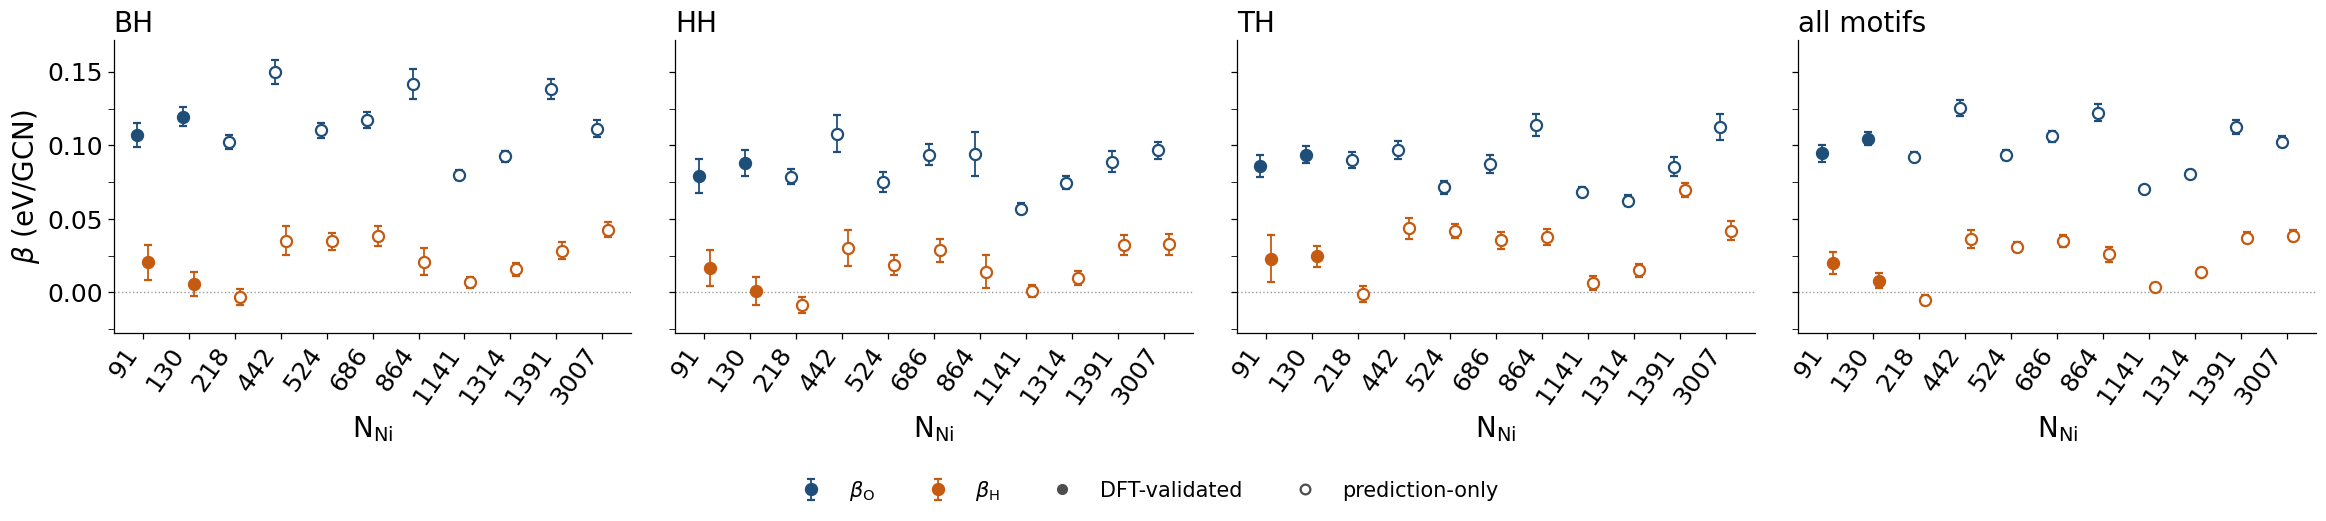

In [20]:
def make_joint_slope_figure() -> None:
    """beta_O and beta_H vs NP size: one panel per motif plus all motifs together."""
    panels = []
    for motif in MAIN_MOTIFS:
        part = usable[usable["motif"] == motif].sort_values("n_atoms")
        panels.append((motif, part.assign(
            err_O=1.96 * part["beta_O_se"], err_H=1.96 * part["beta_H_se"])))
    part = all_motifs.sort_values("n_atoms")
    panels.append(("all motifs", part.assign(
        err_O=part["beta_O_ci_high"] - part["beta_O"], err_H=part["beta_H_ci_high"] - part["beta_H"])))

    systems = sorted(set().union(*(set(p["system"]) for _, p in panels)), key=n_atoms)
    xpos = {s: i for i, s in enumerate(systems)}
    low = min(float((p[["beta_O", "beta_H"]].to_numpy() - p[["err_O", "err_H"]].to_numpy()).min())
              for _, p in panels)
    high = max(float((p[["beta_O", "beta_H"]].to_numpy() + p[["err_O", "err_H"]].to_numpy()).max())
               for _, p in panels)
    pad = 0.08 * (high - low)

    with plt.rc_context(STYLE_PAPER):
        fig, axes = plt.subplots(1, len(panels), figsize=(24.0, 5.4), sharey=True)
        for axis, (title, part) in zip(axes, panels):
            x = np.array([xpos[s] for s in part["system"]], dtype=float)
            for column, error, color, offset, label in (
                ("beta_O", "err_O", "#1f4e79", -0.12, r"$\beta_\mathrm{O}$"),
                ("beta_H", "err_H", "#c55a11", 0.12, r"$\beta_\mathrm{H}$"),
            ):
                for dft_validated, face in ((True, color), (False, "white")):
                    mask = (part["dft_validated"] == dft_validated).to_numpy()
                    axis.errorbar(x[mask] + offset, part[column].to_numpy()[mask],
                                  yerr=part[error].to_numpy()[mask],
                                  fmt="o", ms=8, lw=0, elinewidth=1.3, capsize=3, color=color,
                                  markerfacecolor=face, markeredgecolor=color, markeredgewidth=1.6,
                                  label=label if dft_validated else None)
            axis.axhline(0.0, color="0.6", lw=1.0, ls=":")
            axis.set_xticks(range(len(systems)))
            axis.set_xticklabels([str(n_atoms(s)) for s in systems], rotation=55, ha="right",
                                 fontsize=FONT["tick"])
            axis.set_xlabel(r"$\mathrm{N}_\mathrm{Ni}$")
            axis.set_ylim(low - pad, high + pad)
            axis.set_title(title, loc="left", fontsize=FONT["axis_label"])
            add_minor_ticks(axis, x=False)
        axes[0].set_ylabel(r"$\beta$ (eV/GCN)")
        handles, labels = axes[0].get_legend_handles_labels()
        handles += [Line2D([], [], color="0.3", marker="o", ms=7, lw=0, markerfacecolor="0.3"),
                    Line2D([], [], color="0.3", marker="o", ms=7, lw=0, markerfacecolor="white",
                           markeredgewidth=1.6)]
        labels += ["DFT-validated", "prediction-only"]
        fig.legend(handles, labels, fontsize=FONT["legend_small"], loc="lower center", ncol=4,
                   frameon=False, bbox_to_anchor=(0.5, 0.0))
        fig.tight_layout(rect=(0, 0.09, 1, 1))
        save(fig, HERE / "SI_gcn_O_vs_H_slopes.pdf")


make_joint_slope_figure()

## 9. Motif-slope spread vs bare-surface morphology (Figure S15)

$\sigma_\beta$ is the standard deviation of the three motif slopes $\mathrm{dE_{ads}/dGCN_O}$ (BH, HH, TH; section 2) of each NP.
It is compared with the mean $\bar{q}_6$ and the mean atomic GCN over the surface atoms of the bare NP. The bare-surface
descriptors reproduce `analyze_bare_Ni_for_paper.py`:
- first shell at 3.0 Å; atomic GCN normalised by 12;
- $\bar{q}_6$ averaged over each atom and its first shell;
- surface atoms from a probe-sphere exposure test ($r_\mathrm{atom}$ = 1.24 Å, $r_\mathrm{probe}$ = 1.20 Å, 200 points).

$\mathrm{Ni}_{55}$ has no slopes and is excluded from the correlations. **With ~11 NPs, $|r|$ must exceed about 0.60 for p < 0.05,
and a single NP can shift $r$ by ~0.2. Treat these correlations as a screen.**

In [21]:
FIRST_SHELL_CUTOFF = 3.0
ATOMIC_GCN_CN_MAX = 12
SURFACE_R_ATOM, SURFACE_R_PROBE, SURFACE_N_POINTS = 1.24, 1.20, 200


def first_shell(atoms):
    """First-shell neighbour indices and bond vectors of every atom."""
    i_all, j_all, d_all = neighbor_list("ijD", atoms, FIRST_SHELL_CUTOFF, self_interaction=False)
    keep = np.linalg.norm(d_all, axis=1) > 1.0e-10
    neighbours = [[] for _ in range(len(atoms))]
    vectors = [[] for _ in range(len(atoms))]
    for i, j, vector in zip(i_all[keep], j_all[keep], d_all[keep]):
        neighbours[int(i)].append(int(j))
        vectors[int(i)].append(np.asarray(vector, dtype=float))
    return neighbours, vectors


def atomic_gcn(neighbours) -> np.ndarray:
    cn = np.array([len(entry) for entry in neighbours], dtype=float)
    return np.array([cn[entry].sum() / ATOMIC_GCN_CN_MAX for entry in neighbours])


def qlm_from_vectors(vectors, l: int) -> np.ndarray:
    if not vectors:
        return np.zeros(2 * l + 1, dtype=complex)
    vecs = np.asarray(vectors, dtype=float)
    r = np.linalg.norm(vecs, axis=1)
    polar = np.arccos(np.clip(vecs[:, 2] / r, -1.0, 1.0))
    azimuth = np.mod(np.arctan2(vecs[:, 1], vecs[:, 0]), 2.0 * np.pi)
    return np.array([np.mean(spherical_harmonic(l, m, polar, azimuth)) for m in range(-l, l + 1)])


def rotational_invariant_q(qlm, l: int) -> float:
    return float(np.sqrt(4.0 * np.pi / (2 * l + 1) * np.sum(np.abs(qlm) ** 2)))


def qbar(neighbours, vectors, l: int = 6) -> np.ndarray:
    """Lechner-Dellago qbar_l: q_lm averaged over each atom and its first shell."""
    qlm = np.array([qlm_from_vectors(entry, l) for entry in vectors], dtype=complex)
    return np.array([rotational_invariant_q(qlm[[i] + neighbours[i]].mean(axis=0), l)
                     for i in range(len(neighbours))])


def fibonacci_sphere(n_points: int) -> np.ndarray:
    k = np.arange(n_points, dtype=float)
    z = 1.0 - 2.0 * (k + 0.5) / n_points
    r_xy = np.sqrt(np.clip(1.0 - z * z, 0.0, None))
    phi = np.pi * (3.0 - np.sqrt(5.0)) * k
    return np.column_stack((r_xy * np.cos(phi), r_xy * np.sin(phi), z))


def surface_atoms(positions: np.ndarray) -> np.ndarray:
    """Atoms with any probe-accessible point on their contact shell."""
    sphere = fibonacci_sphere(SURFACE_N_POINTS)
    shell = SURFACE_R_ATOM + SURFACE_R_PROBE
    surface = []
    for i, centre in enumerate(positions):
        points = centre[None, :] + shell * sphere
        distance = np.linalg.norm(positions - centre[None, :], axis=1)
        others = positions[(distance <= 2.0 * shell + 1.0e-12) & (np.arange(len(positions)) != i)]
        buried = np.zeros(SURFACE_N_POINTS, dtype=bool)
        for other in others:
            buried |= np.linalg.norm(points - other[None, :], axis=1) < shell
            if buried.all():
                break
        if (~buried).any():
            surface.append(i)
    return np.asarray(surface, dtype=int)


morph_rows = []
for system in retained:
    atoms = read(bare_structure(system), index=-1)
    neighbours, vectors = first_shell(atoms)
    surf = surface_atoms(atoms.get_positions())
    qbar6 = qbar(neighbours, vectors, 6)[surf]
    gcn = atomic_gcn(neighbours)[surf]
    morph_rows.append({
        "system": system, "n_atoms": n_atoms(system), "n_surface": len(surf),
        "q6_mean": float(qbar6.mean()), "gcn_atomic_mean": float(gcn.mean()),
    })
    print(f"  [{system}] {len(surf)} surface atoms, qbar6 {qbar6.mean():.3f}, atomic GCN {gcn.mean():.2f}")
morphology = pd.DataFrame(morph_rows)

  [Ni55] 42 surface atoms, qbar6 0.320, atomic GCN 5.29
  [Ni91] 64 surface atoms, qbar6 0.260, atomic GCN 5.47
  [Ni130] 88 surface atoms, qbar6 0.356, atomic GCN 5.78
  [Ni218] 136 surface atoms, qbar6 0.337, atomic GCN 6.09
  [Ni442] 207 surface atoms, qbar6 0.525, atomic GCN 5.74
  [Ni524] 242 surface atoms, qbar6 0.527, atomic GCN 5.99
  [Ni686] 289 surface atoms, qbar6 0.507, atomic GCN 6.00
  [Ni864] 352 surface atoms, qbar6 0.563, atomic GCN 5.90
  [Ni1141] 443 surface atoms, qbar6 0.356, atomic GCN 6.43
  [Ni1314] 487 surface atoms, qbar6 0.344, atomic GCN 6.55
  [Ni1391] 499 surface atoms, qbar6 0.571, atomic GCN 6.30
  [Ni3007] 721 surface atoms, qbar6 0.575, atomic GCN 5.96


In [22]:
sep_rows = []
o_slopes = slopes[(slopes["descriptor"] == "o_site_gcn") & slopes["motif"].isin(MAIN_MOTIFS)]
for system, data in o_slopes.groupby("system"):
    beta = {row.motif: (row.slope if row.usable else np.nan) for row in data.itertuples()}
    b = {motif: beta.get(motif, np.nan) for motif in MAIN_MOTIFS}
    values = np.array([b[m] for m in MAIN_MOTIFS], dtype=float)
    complete = bool(np.all(np.isfinite(values)))
    sep_rows.append({
        "system": system, "n_atoms": n_atoms(system),
        "dft_validated": bool(data["dft_validated"].iloc[0]),
        "beta_BH": b["BH"], "beta_HH": b["HH"], "beta_TH": b["TH"],
        "sigma_beta": float(np.std(values, ddof=1)) if complete else np.nan,
        "complete": complete,
    })
summary = (pd.DataFrame(sep_rows).merge(morphology, on=["system", "n_atoms"], how="left")
           .sort_values("n_atoms"))
summary.to_csv(HERE / "slope_vs_morphology_summary.csv", index=False)
morph_usable = summary[summary["complete"]].copy()
print(f"{len(morph_usable)} of {len(summary)} particles have all three motif slopes; excluded: "
      f"{[s for s in summary['system'] if s not in set(morph_usable['system'])]}")



def relate(data, xcol, ycol) -> dict:
    finite = np.isfinite(data[xcol]) & np.isfinite(data[ycol])
    x, y = data.loc[finite, xcol].to_numpy(float), data.loc[finite, ycol].to_numpy(float)
    pr, pp = pearsonr(x, y)
    sr, sp = spearmanr(x, y)
    slope, intercept = np.polyfit(x, y, 1)
    residual = y - (slope * x + intercept)
    return {"x": xcol, "y": ycol, "n": len(x), "pearson_r": pr, "pearson_p": pp,
            "spearman_rho": sr, "spearman_p": sp, "ols_slope": slope,
            "ols_r2": 1 - np.sum(residual**2) / np.sum((y - y.mean()) ** 2)}


correlations = pd.DataFrame([relate(morph_usable, x, "sigma_beta")
                             for x in ("q6_mean", "gcn_atomic_mean")])
correlations.to_csv(HERE / "slope_morphology_correlations.csv", index=False)
print(morph_usable[["system", "beta_BH", "beta_HH", "beta_TH", "sigma_beta", "q6_mean",
                    "gcn_atomic_mean"]].to_string(index=False, float_format=lambda v: f"{v:.4f}"))
correlations.round(3)

11 of 12 particles have all three motif slopes; excluded: ['Ni55']
system  beta_BH  beta_HH  beta_TH  sigma_beta  q6_mean  gcn_atomic_mean
  Ni91   0.1064   0.0783   0.0838      0.0149   0.2604           5.4674
 Ni130   0.1192   0.0881   0.0921      0.0169   0.3557           5.7822
 Ni218   0.1021   0.0773   0.0898      0.0124   0.3368           6.0864
 Ni442   0.1507   0.1033   0.1009      0.0281   0.5246           5.7367
 Ni524   0.1123   0.0750   0.0760      0.0212   0.5273           5.9852
 Ni686   0.1213   0.0934   0.0906      0.0170   0.5075           6.0009
 Ni864   0.1457   0.0937   0.1211      0.0260   0.5628           5.8991
Ni1141   0.0806   0.0571   0.0687      0.0118   0.3561           6.4304
Ni1314   0.0949   0.0763   0.0640      0.0156   0.3442           6.5484
Ni1391   0.1441   0.0826   0.1109      0.0308   0.5712           6.2989
Ni3007   0.1186   0.1017   0.1480      0.0234   0.5749           5.9632


,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p,ols_slope,ols_r2
0,q6_mean,sigma_beta,11,0.834,0.001,0.809,0.003,0.046,0.695
1,gcn_atomic_mean,sigma_beta,11,-0.140,0.682,-0.264,0.433,-0.003,0.020


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


Wrote SI_slope_separation_vs_morphology.pdf


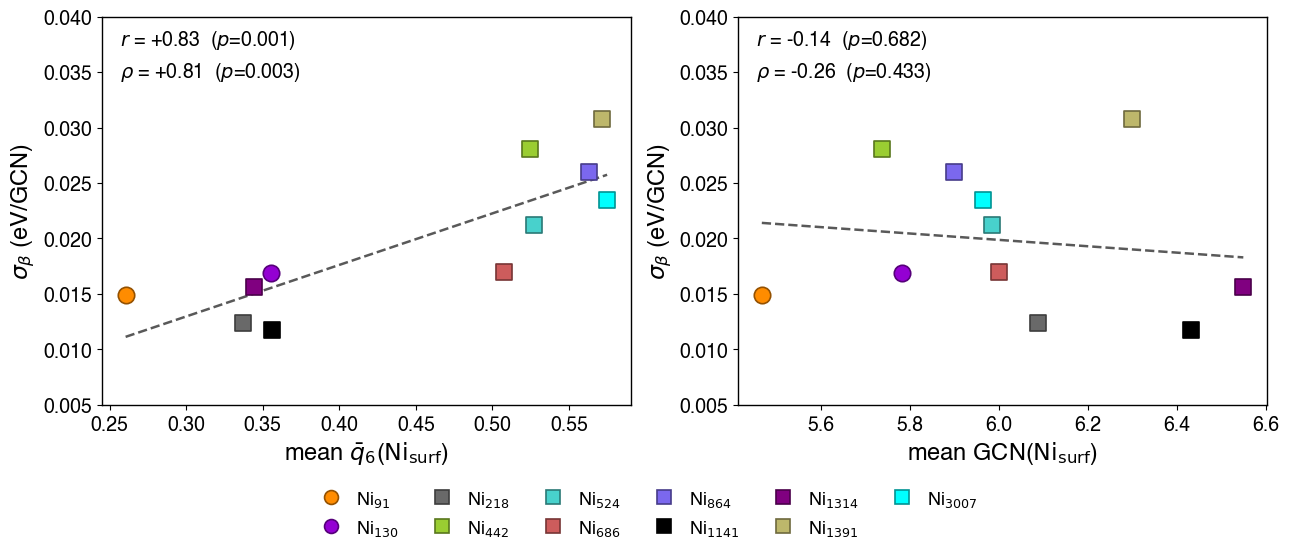

In [23]:
LABEL_SIGMA = r"$\sigma_\beta$ (eV/GCN)"
SI_PANELS = [("q6_mean", r"mean $\bar{q}_6$($\mathrm{Ni}_{\mathrm{surf}}$)"),
             ("gcn_atomic_mean", r"mean GCN($\mathrm{Ni}_{\mathrm{surf}}$)")]
MORPH_FONT = {"axis_label": 17, "tick": 14, "legend": 13, "stat": 14}
SI_YLIM, SI_YTICK_STEP = (0.005, 0.035), 0.005


def system_colors(system: str) -> tuple[str, str]:
    face = NP_FACE_COLORS.get(system, "#A8CAC7")
    return face, to_hex(np.clip(np.asarray(to_rgb(face)) * 0.58, 0.0, 1.0))


def np_marker(dft_validated: bool) -> str:
    return "o" if dft_validated else "s"  # circles DFT-validated, squares prediction-only


def p_text(value: float) -> str:
    return r"$p$<0.001" if value < 0.001 else f"$p$={value:.3f}"


def fit_line(axis, x, y, lw):
    coefficients = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 40)
    axis.plot(xs, np.polyval(coefficients, xs), color="0.35", lw=lw, ls="--", zorder=2)
    return pearsonr(x, y), spearmanr(x, y)


def system_legend(figure, data, fontsize, markersize, anchor_y) -> None:
    handles = []
    for row in data.sort_values("n_atoms").itertuples():
        face, edge = system_colors(row.system)
        handles.append(Line2D([0], [0], marker=np_marker(row.dft_validated), linestyle="None",
                              markersize=markersize, markerfacecolor=face, markeredgecolor=edge,
                              markeredgewidth=1.2, label=display_name(row.system)))
    figure.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, anchor_y), ncol=6,
                  frameon=False, fontsize=fontsize, handletextpad=0.4, columnspacing=1.4)


def make_figure_s15(data) -> None:
    sigma = data["sigma_beta"].to_numpy(float)
    ylim = (min(SI_YLIM[0], np.floor(sigma.min() / SI_YTICK_STEP) * SI_YTICK_STEP),
            max(SI_YLIM[1], np.ceil(sigma.max() / SI_YTICK_STEP + 1) * SI_YTICK_STEP))
    with plt.rc_context(STYLE_MORPHOLOGY):
        fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.6))
        for axis, (xcol, xlabel) in zip(axes, SI_PANELS):
            (pr, pp), (sr, sp) = fit_line(axis, data[xcol].to_numpy(float), sigma, lw=1.8)
            axis.text(0.035, 0.97, f"$r$ = {pr:+.2f}  ({p_text(pp)})\n"
                      rf"$\rho$ = {sr:+.2f}  ({p_text(sp)})", transform=axis.transAxes,
                      va="top", ha="left", fontsize=MORPH_FONT["stat"], linespacing=1.5)
            for row in data.itertuples():
                face, edge = system_colors(row.system)
                axis.scatter(getattr(row, xcol), row.sigma_beta, s=140, color=face,
                             marker=np_marker(row.dft_validated), edgecolor=edge, linewidth=1.2, zorder=3)
            axis.set_xlabel(xlabel, fontsize=MORPH_FONT["axis_label"])
            axis.set_ylabel(LABEL_SIGMA, fontsize=MORPH_FONT["axis_label"])
            axis.set_ylim(*ylim)
            axis.yaxis.set_major_locator(MultipleLocator(SI_YTICK_STEP))
            axis.tick_params(labelsize=MORPH_FONT["tick"])
        system_legend(fig, data, MORPH_FONT["legend"], markersize=10, anchor_y=0.0)
        fig.tight_layout(rect=(0, 0.13, 1, 1))
        save(fig, HERE / "SI_slope_separation_vs_morphology.pdf")


make_figure_s15(morph_usable)

## 10. Strongest-binding retained BH, HH and TH per NP

For each NP and motif, the retained candidate with the lowest $\mathrm{E}_\mathrm{ads}$, with its O and H site classification.
Local environment of a surface Ni atom (bare geometry, first shell at 3.0 Å, outward normal opposite the mean bond,
in-plane neighbours within ±30° of the local plane):

| class | rule |
|---|---|
| edge_vertex | CN ≤ 6 |
| 100 | CN = 8, 4 in-plane neighbours, regular 90° pattern (RMS gap ≤ 18°) |
| 111 | CN = 9, 6 in-plane neighbours, regular 60° pattern |
| step_110_311 | remaining CN 7–8 atoms, or 5 in-plane neighbours |
| other | everything else |

A site is edge-containing if any anchor is edge_vertex, otherwise step-containing if any anchor is step_110_311.
It is (100)- or (111)-like only when all anchors share that class and lie in one local plane (normals within 10°,
anchor bonds tilted ≤ 10°). Everything else is boundary/other. **Reported Ni indices are one-based** (stored index + 1).

In [24]:
LAYER_COS_TOL = 0.50
TERRACE_GAP_RMS_MAX_DEG = 18.0
TERRACE_NORMAL_MISMATCH_MAX_DEG = 10.0
TERRACE_BOND_TILT_MAX_DEG = 10.0
SITE_LABEL = {"edge_vertex": "edge-containing", "step_110_311": "step/edge-containing",
              "100": "(100)-like", "111": "(111)-like", "boundary_other": "boundary/other"}


def projected_gap_rms_deg(vectors, normal) -> float:
    """RMS angular-gap error after projecting bonds into the local plane."""
    if len(vectors) < 2:
        return np.nan
    ref = np.array([1.0, 0.0, 0.0])
    if abs(float(np.dot(ref, normal))) > 0.9:
        ref = np.array([0.0, 1.0, 0.0])
    e1 = ref - np.dot(ref, normal) * normal
    e1 /= np.linalg.norm(e1)
    e2 = np.cross(normal, e1)
    angles = sorted(np.degrees(np.arctan2(float(np.dot(v, e2)), float(np.dot(v, e1)))) % 360.0
                    for v in vectors)
    gaps = np.diff(angles + [angles[0] + 360.0])
    return float(np.sqrt(np.mean((gaps - 360.0 / len(angles)) ** 2)))


def atom_environments(positions):
    """Local environment class and outward normal of every Ni atom."""
    distance = np.linalg.norm(positions[:, None, :] - positions[None, :, :], axis=-1)
    np.fill_diagonal(distance, np.inf)
    classes, normals = [], []
    for i in range(len(positions)):
        bonds = positions[distance[i] < NI_NI_CUTOFF] - positions[i]
        cn = len(bonds)
        normal = None
        if cn:
            mean_bond = bonds.mean(axis=0)
            if np.linalg.norm(mean_bond) >= 1.0e-6:
                normal = -mean_bond / np.linalg.norm(mean_bond)
        if normal is None:
            classes.append("other")
            normals.append(None)
            continue
        in_plane = bonds[np.abs(bonds @ normal) / np.linalg.norm(bonds, axis=1) <= LAYER_COS_TOL]
        gap_rms, n_in = projected_gap_rms_deg(in_plane, normal), len(in_plane)
        if cn <= 6:
            label = "edge_vertex"
        elif cn == 8 and n_in == 4 and gap_rms <= TERRACE_GAP_RMS_MAX_DEG:
            label = "100"
        elif cn == 9 and n_in == 6 and gap_rms <= TERRACE_GAP_RMS_MAX_DEG:
            label = "111"
        elif cn in (7, 8) or n_in == 5:
            label = "step_110_311"
        else:
            label = "other"
        classes.append(label)
        normals.append(normal)
    return classes, normals


def site_environment(anchors, positions, classes, normals) -> str:
    normal_angles, bond_tilts = [], []
    for position, i in enumerate(anchors):
        for j in anchors[position + 1 :]:
            ni, nj = normals[i], normals[j]
            if ni is None or nj is None:
                continue
            normal_angles.append(float(np.degrees(np.arccos(np.clip(np.dot(ni, nj), -1.0, 1.0)))))
            bond = positions[j] - positions[i]
            bond /= np.linalg.norm(bond)
            for normal in (ni, nj):
                bond_tilts.append(abs(float(np.degrees(np.arcsin(np.clip(np.dot(bond, normal), -1.0, 1.0))))))
    same_plane = (max(normal_angles, default=0.0) <= TERRACE_NORMAL_MISMATCH_MAX_DEG
                  and max(bond_tilts, default=0.0) <= TERRACE_BOND_TILT_MAX_DEG)
    anchor_classes = {classes[i] for i in anchors}
    if "edge_vertex" in anchor_classes:
        return "edge_vertex"
    if "step_110_311" in anchor_classes:
        return "step_110_311"
    if anchor_classes == {"100"} and same_plane:
        return "100"
    if anchor_classes == {"111"} and same_plane:
        return "111"
    return "boundary_other"


def one_based(anchors) -> str:
    return ",".join(str(index + 1) for index in sorted(anchors))


def describe_site(anchors, site_type, gcn, positions, classes, normals):
    site_class = site_environment(anchors, positions, classes, normals)
    cn_max = GCN_CN_MAX[site_type]
    return site_class, (f"{{{one_based(anchors)}}}  {SITE_LABEL[site_class]}  "
                        f"[anchors: {'|'.join(classes[i] for i in sorted(anchors))}]  "
                        f"GCN {gcn:.3f} (sum CN={int(round(gcn * cn_max))}, CN_max={cn_max})")

In [25]:
best_rows = []
for system, data in retained.items():
    positions = read_xyz_positions(bare_structure(system))
    classes, normals = atom_environments(positions)
    status = "DFT-validated" if data["dft_validated"].iloc[0] else "prediction-only"
    print(f"\n{'#' * 96}\n{system} ({status}): {len(data):,} retained candidates\n{'#' * 96}")
    for motif in MAIN_MOTIFS:
        group = data[data["motif"] == motif]
        if group.empty:
            print(f"\n{motif}: no retained candidate")
            continue
        row = group.loc[group[ENERGY_COL].idxmin()]
        o_anchors = parse_anchor_indices(row["o_anchor_idx"])
        h_anchors = parse_anchor_indices(row["h_anchor_idx"])
        o_class, o_text = describe_site(o_anchors, row["o_type"], row["o_site_gcn"], positions, classes, normals)
        h_class, h_text = describe_site(h_anchors, row["h_type"], row["h_site_gcn"], positions, classes, normals)
        print(f"\n{motif}   (n = {len(group):,})   rank {int(row['rank'])}   "
              f"E_ads {row[ENERGY_COL]:+.3f} eV   s_ret {row['retention_probability']:.3f}")
        print(f"    O site: {o_text}")
        print(f"    H site: {h_text}")
        best_rows.append({"system": system, "motif": motif, "E_ads_eV": row[ENERGY_COL],
                          "rank": int(row["rank"]), "s_ret": row["retention_probability"],
                          "O_site": f"{{{one_based(o_anchors)}}}", "O_class": SITE_LABEL[o_class],
                          "GCN_O": row["o_site_gcn"], "H_site": f"{{{one_based(h_anchors)}}}",
                          "H_class": SITE_LABEL[h_class], "GCN_H": row["h_site_gcn"]})
best_sites = pd.DataFrame(best_rows)


################################################################################################
Ni55 (DFT-validated): 3,480 retained candidates
################################################################################################

BH   (n = 1,620)   rank 1   E_ads -1.349 eV   s_ret 1.000
    O site: {27,37}  edge-containing  [anchors: edge_vertex|step_110_311]  GCN 4.333 (sum CN=78, CN_max=18)
    H site: {18,26,27}  edge-containing  [anchors: step_110_311|step_110_311|edge_vertex]  GCN 4.364 (sum CN=96, CN_max=22)

HH   (n = 1,320)   rank 361   E_ads -1.246 eV   s_ret 0.999
    O site: {23,32,33}  edge-containing  [anchors: edge_vertex|step_110_311|step_110_311]  GCN 4.364 (sum CN=96, CN_max=22)
    H site: {16,22,23}  edge-containing  [anchors: step_110_311|step_110_311|edge_vertex]  GCN 4.364 (sum CN=96, CN_max=22)

TH   (n = 540)   rank 12597   E_ads -0.814 eV   s_ret 1.000
    O site: {29}  edge-containing  [anchors: edge_vertex]  GCN 4.333 (sum CN=52, CN_max=12)
    

In [26]:
for motif in MAIN_MOTIFS:
    print(f"\n{motif}")
    print(best_sites[best_sites["motif"] == motif].drop(columns="motif")
          .to_string(index=False, float_format=lambda value: f"{value:.3f}"))


BH
system  E_ads_eV  rank  s_ret      O_site         O_class  GCN_O           H_site              H_class  GCN_H
  Ni55    -1.349     1  1.000     {27,37} edge-containing  4.333       {18,26,27}      edge-containing  4.364
  Ni91    -1.509     6  0.900     {26,77} edge-containing  4.611       {77,83,88}      edge-containing  4.182
 Ni130    -1.515     5  0.996   {116,124} edge-containing  3.500      {17,98,124}      edge-containing  4.455
 Ni218    -1.556     4  0.952     {5,155} edge-containing  4.500    {146,155,172} step/edge-containing  5.636
 Ni442    -1.516    12  0.980   {130,326} edge-containing  3.556    {326,327,330}      edge-containing  5.545
 Ni524    -1.507     6  1.000   {303,363} edge-containing  3.278    {303,331,367}      edge-containing  5.091
 Ni686    -1.550     2  0.994   {250,468} edge-containing  3.111    {210,468,640}      edge-containing  4.773
 Ni864    -1.648     9  1.000    {99,121} edge-containing  2.667    {123,127,271} step/edge-containing  5.273
Ni1141